# Real-Time E-Commerce Intelligence and Recommendation System
## Using Apache Spark and Cloud Computing
**Capstone Project: Big Data and Cloud Technology**

| | |
|---|---|
| Team / Student(s) | Pavithra K M, Asna Abbas |
| Institution / Department | DACS |
| Date | November 2026 |

### Abstract
Online shops produce millions of events every day (views, carts, purchases). A recommender that is only retrained in batch cannot react when a user's interest changes. This project builds a **real-time recommendation system** with **PySpark, Spark SQL, MLlib and Structured Streaming**:

* historical data trains an **ALS** collaborative-filtering model,
* product similarity is found with **shingling, MinHash and LSH**,
* live events are analysed with **windows** to find trending products and categories,
* everything is merged by a **hybrid recommender** served through a **REST API** packaged in **Docker** and deployable on a cloud Spark platform.

### How this notebook is organised
Every step is **one text cell (what and why) followed by one code cell** that runs the step *and* draws its figure. Every figure is also saved to `capstone_work/figures/`, so it can go straight into the report. A small dictionary `R` collects the key numbers, and the last section builds the summary from it, so no result is typed by hand.

## 1. System architecture

**Data (history + live events) → Spark processing → ALS + LSH → hybrid recommender → REST API → web app / dashboard.**

* **Batch layer:** Spark jobs over the full history (cleaning, ALS, LSH).
* **Speed layer:** Structured Streaming over live events (trends, recent interest).
* **Serving layer:** the API merges both layers when a request arrives.

Spark is used for both layers because batch and streaming share the same DataFrame API.

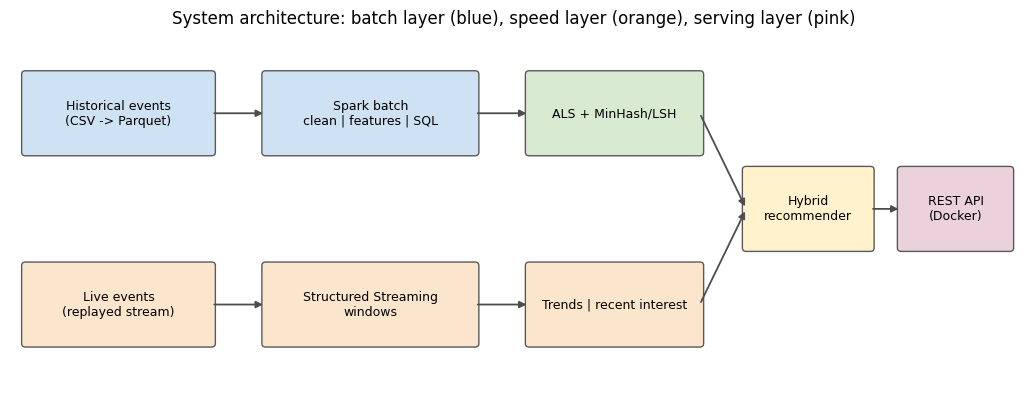

In [1]:
from matplotlib.patches import FancyBboxPatch
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 4.6)); ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, 5)
boxes = {  # name: (x, y, width, height, colour)
    "Historical events\n(CSV -> Parquet)": (0.2, 3.3, 2.4, 1.1, "#cfe2f3"),
    "Live events\n(replayed stream)":      (0.2, 0.6, 2.4, 1.1, "#fce5cd"),
    "Spark batch\nclean | features | SQL": (3.3, 3.3, 2.7, 1.1, "#cfe2f3"),
    "Structured Streaming\nwindows":       (3.3, 0.6, 2.7, 1.1, "#fce5cd"),
    "ALS + MinHash/LSH":                   (6.7, 3.3, 2.2, 1.1, "#d9ead3"),
    "Trends | recent interest":            (6.7, 0.6, 2.2, 1.1, "#fce5cd"),
    "Hybrid\nrecommender":                 (9.5, 1.95, 1.6, 1.1, "#fff2cc"),
    "REST API\n(Docker)":                  (11.5, 1.95, 1.4, 1.1, "#ead1dc")}
names = list(boxes)
for name, (x, y, w, h, c) in boxes.items():
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=c, ec="0.35"))
    ax.text(x + w / 2, y + h / 2, name, ha="center", va="center", fontsize=9)
edge = lambda n, side: (boxes[n][0] + boxes[n][2], boxes[n][1] + boxes[n][3] / 2) if side == "r" else (boxes[n][0], boxes[n][1] + boxes[n][3] / 2)
for a, b in [(0, 2), (1, 3), (2, 4), (3, 5), (4, 6), (5, 6), (6, 7)]:
    ax.annotate("", xy=edge(names[b], "l"), xytext=edge(names[a], "r"), arrowprops=dict(arrowstyle="-|>", color="0.3", lw=1.3))
ax.set_title("System architecture: batch layer (blue), speed layer (orange), serving layer (pink)")
plt.show()

## 2. Setup

Python 3.9+ and Java 11/17 are required. The first cell installs the packages; the second holds **all settings**. Edit only that cell:

* `SAMPLE_FRACTION = 0.05` gives a quick first run on 5% of the data; use `1.0` for the full month.
* Lower `DRIVER_MEMORY` (for example `"4g"`) on a small laptop.

In [2]:
%pip install -q pyspark==3.5.1 pandas numpy matplotlib pyarrow fastapi uvicorn httpx setuptools

You should consider upgrading via the '/cm/local/apps/python39/bin/python3.9 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, sys, time, json, random, shutil, threading, subprocess, warnings
from pathlib import Path
from datetime import datetime
from itertools import product as iproduct
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import clear_output

# ===================== SETTINGS (edit here only) =====================
WORK_DIR         = Path("./capstone_work")   # all outputs; use an S3 / GCS / HDFS path on the cloud
RAW_FILES        = ["2019-Oct.csv"]          # add "2019-Nov.csv" for about 2x more data
SAMPLE_FRACTION  = 0.05                      # 0.05 = quick run, 1.0 = full data
DRIVER_MEMORY    = "8g"
SHUFFLE_PARTS    = 64                        # about 2-3x the number of cores
RANDOM_SEED      = 42
N_EVAL_USERS     = 20000                     # users used for Precision/Recall
N_HYB            = 3000                      # users used for the hybrid comparison
SIM_POOL         = 30000                     # most-viewed products used in the LSH similarity join
N_SIM_QUERIES    = 100                       # products queried for LSH precision
N_RECALL_SAMPLE  = 1500                      # products used for the exact-vs-LSH recall check
N_SERVING_USERS  = 50000                     # users whose recommendations are exported for the API
N_BATCHES, ROWS_PER_BATCH, BATCH_INTERVAL_S, SIM_STEP_S = 60, 1500, 3.0, 30   # stream replay
# =====================================================================

RAW_DIR, FIG_DIR, SERVE_DIR = WORK_DIR / "raw", WORK_DIR / "figures", WORK_DIR / "serving"
for d in (RAW_DIR, FIG_DIR, SERVE_DIR): d.mkdir(parents=True, exist_ok=True)
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)

from pyspark.sql import SparkSession, functions as F, Window, types as T
spark = (SparkSession.builder.appName("EcomRecommender").master("local[*]")      # cluster: "yarn" or "spark://host:7077"
         .config("spark.driver.memory", DRIVER_MEMORY).config("spark.sql.shuffle.partitions", SHUFFLE_PARTS)
         .config("spark.sql.adaptive.enabled", "true").config("spark.sql.session.timeZone", "UTC")
         .config("spark.local.dir", str(WORK_DIR / "spark_tmp")).getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism, "| UI:", spark.sparkContext.uiWebUrl)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False})
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = (plt.get_cmap("tab10")(i) for i in (0, 1, 2, 3, 4, 7))

def save(name):
    # tight layout -> save to figures/<name>.png -> show
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

def timeit(f):
    t0 = time.time(); out = f(); return out, time.time() - t0

R = {}   # key results, filled by the cells below and summarised in Section 11

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/21 17:01:27 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/21 17:01:27 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


Spark 3.5.1 | cores: 256 | UI: http://kudsit-dgxserver.cm.cluster:4040


## 3. Data collection and loading

**Dataset:** *eCommerce behavior data from a multi-category store* (REES46 on Kaggle), a real event log of an online shop. One month is about 5 GB and 42 million rows.

| Column | Meaning |
|---|---|
| `event_time` | time of the event (UTC) |
| `event_type` | `view`, `cart`, `remove_from_cart`, `purchase` |
| `product_id`, `category_id`, `category_code`, `brand`, `price` | product data (category and brand are often missing) |
| `user_id`, `user_session` | the user and the browsing session |

**What the dataset does not contain, and how we handle it**
* *Ratings:* we derive an implicit rating from behaviour: view = 1, cart = 3, purchase = 5.
* *Product descriptions:* we build a short text from category path, brand and price band, and use it for shingling.
* *Live events:* the live feed is **simulated** by replaying real events (Section 8).

The CSV is converted to **Parquet**: it is columnar and compressed, keeps the schema, and lets Spark read only the columns and partitions a query needs. The cell downloads the file automatically if it is not in `capstone_work/raw/`.

rows: 2,121,219 | partitions: 143
root
 |-- event_time: timestamp (nullable = true)
 |-- event_type: string (nullable = true)
 |-- product_id: long (nullable = true)
 |-- category_id: long (nullable = true)
 |-- category_code: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- price: double (nullable = true)
 |-- user_id: long (nullable = true)
 |-- user_session: string (nullable = true)
 |-- event_date: date (nullable = true)



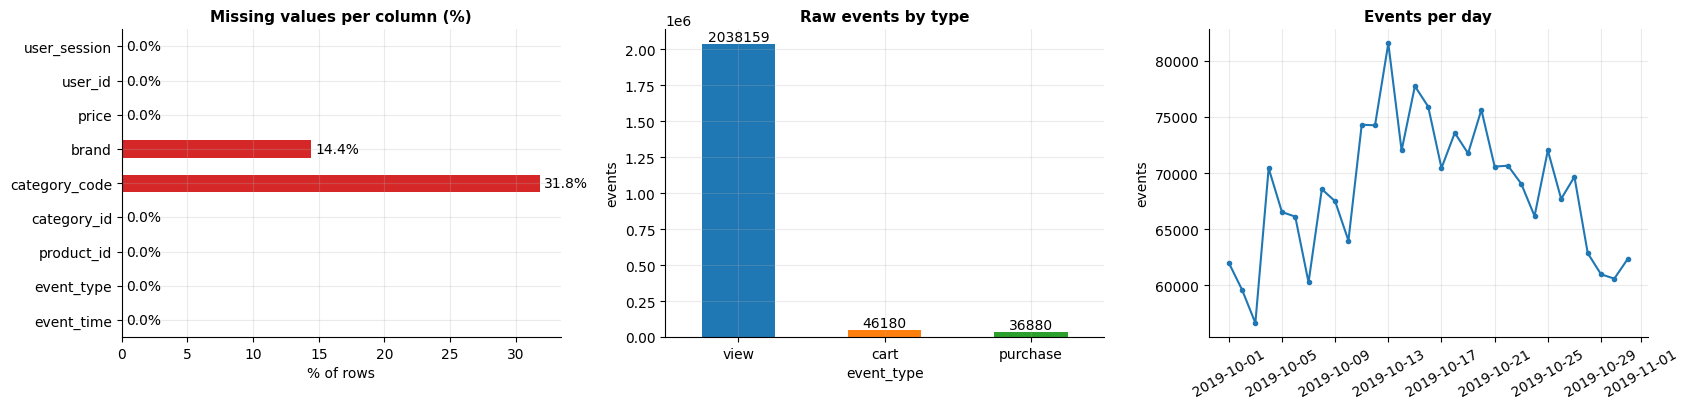

In [4]:
for f in RAW_FILES:                                   # download once if missing (about 1.7 GB per month)
    p = RAW_DIR / f
    if not p.exists():
        print("downloading", f, "...")
        subprocess.run(f"curl -L -o {p}.gz https://data.rees46.com/datasets/marketplace/{f}.gz && gunzip -f {p}.gz", shell=True, check=True)

schema = T.StructType([T.StructField(n, t) for n, t in [
    ("event_time", T.StringType()), ("event_type", T.StringType()), ("product_id", T.LongType()), ("category_id", T.LongType()),
    ("category_code", T.StringType()), ("brand", T.StringType()), ("price", T.DoubleType()), ("user_id", T.LongType()),
    ("user_session", T.StringType())]])

raw = spark.read.option("header", True).schema(schema).csv([str(RAW_DIR / f) for f in RAW_FILES])
if SAMPLE_FRACTION < 1.0:
    raw = raw.sample(False, SAMPLE_FRACTION, RANDOM_SEED)
events = (raw.withColumn("event_time", F.to_timestamp(F.regexp_replace("event_time", " UTC$", ""), "yyyy-MM-dd HH:mm:ss"))
             .withColumn("event_date", F.to_date("event_time")))
events.write.mode("overwrite").partitionBy("event_date").parquet(str(WORK_DIR / "parquet" / "events_raw"))
events_raw = spark.read.parquet(str(WORK_DIR / "parquet" / "events_raw"))

n_raw = events_raw.count(); R["rows_raw"] = n_raw
nulls = events_raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in events_raw.columns]).first().asDict()
null_pct = (pd.Series(nulls) / n_raw * 100).drop("event_date")
print(f"rows: {n_raw:,} | partitions: {events_raw.rdd.getNumPartitions()}"); events_raw.printSchema()

type_cnt = events_raw.groupBy("event_type").count().toPandas().set_index("event_type")["count"].sort_values(ascending=False)
daily = events_raw.groupBy("event_date").count().orderBy("event_date").toPandas()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
null_pct.plot.barh(ax=ax[0], color=[RED if v > 0 else GREEN for v in null_pct]); ax[0].bar_label(ax[0].containers[0], fmt="%.1f%%", padding=3)
ax[0].set_title("Missing values per column (%)"); ax[0].set_xlabel("% of rows")
type_cnt.plot.bar(ax=ax[1], rot=0, color=[BLUE, ORANGE, GREEN, RED][:len(type_cnt)]); ax[1].bar_label(ax[1].containers[0], fmt="%d")
ax[1].set_title("Raw events by type"); ax[1].set_ylabel("events")
ax[2].plot(daily["event_date"], daily["count"], marker="o", ms=3, color=BLUE); ax[2].tick_params(axis="x", rotation=30)
ax[2].set_title("Events per day"); ax[2].set_ylabel("events")
save("01_data_profile")

## 4. Preprocessing and exploration

**Cleaning rules:** drop rows with a missing user, product, time or event type; keep only `price > 0`; keep only `view`, `cart` and `purchase`; remove exact duplicates; fill missing category and brand with `"unknown"`. We also add `hour`, `dow` (day of week) and `main_category` (first part of the category path) for the analysis.

The left figure shows how many rows each rule affects (rules overlap, so the bars do not add up); the right figure shows the total effect. Then **Spark SQL** answers business questions (conversion funnel, best-selling products and brands), and an exploration figure shows the daily rhythm, categories, prices and how concentrated the interactions are.

raw: 2,121,219 | clean: 2,117,673 | removed: 3,546 (0.17%)


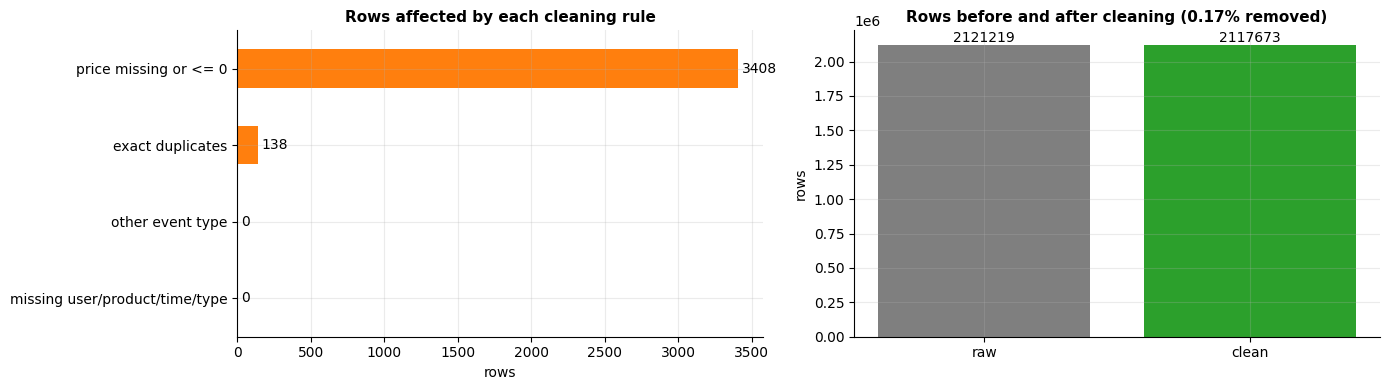

In [5]:
key_missing = (F.col("user_id").isNull() | F.col("product_id").isNull() | F.col("event_time").isNull() | F.col("event_type").isNull())
viol = events_raw.select(
    F.sum(key_missing.cast("int")).alias("missing user/product/time/type"),
    F.sum((F.col("price").isNull() | (F.col("price") <= 0)).cast("int")).alias("price missing or <= 0"),
    F.sum((~F.col("event_type").isin("view", "cart", "purchase")).cast("int")).alias("other event type")).first().asDict()

filtered = (events_raw.dropna(subset=["user_id", "product_id", "event_time", "event_type"])
            .filter((F.col("price") > 0) & F.col("event_type").isin("view", "cart", "purchase")))
n_filtered = filtered.count()
(filtered.dropDuplicates(["user_id", "product_id", "event_type", "event_time", "user_session"])
    .withColumn("category_code", F.coalesce("category_code", F.lit("unknown")))
    .withColumn("brand", F.coalesce("brand", F.lit("unknown")))
    .withColumn("main_category", F.split("category_code", r"\.").getItem(0))
    .withColumn("hour", F.hour("event_time")).withColumn("dow", F.dayofweek("event_time"))
    .write.mode("overwrite").parquet(str(WORK_DIR / "parquet" / "events_clean")))
clean = spark.read.parquet(str(WORK_DIR / "parquet" / "events_clean")).cache()
n_clean = clean.count(); n_dup = n_filtered - n_clean; R["rows_clean"] = n_clean
print(f"raw: {n_raw:,} | clean: {n_clean:,} | removed: {n_raw - n_clean:,} ({100 * (n_raw - n_clean) / n_raw:.2f}%)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
v = pd.Series({**viol, "exact duplicates": n_dup}).fillna(0).sort_values()
v.plot.barh(ax=ax[0], color=ORANGE); ax[0].bar_label(ax[0].containers[0], fmt="%d", padding=3)
ax[0].set_title("Rows affected by each cleaning rule"); ax[0].set_xlabel("rows")
ax[1].bar(["raw", "clean"], [n_raw, n_clean], color=[GREY, GREEN]); ax[1].bar_label(ax[1].containers[0], fmt="%d")
ax[1].set_title(f"Rows before and after cleaning ({100 * (n_raw - n_clean) / n_raw:.2f}% removed)"); ax[1].set_ylabel("rows")
save("02_cleaning_impact")

 users  products  sessions  categories  brands
967811    105497   1650476         127    2986


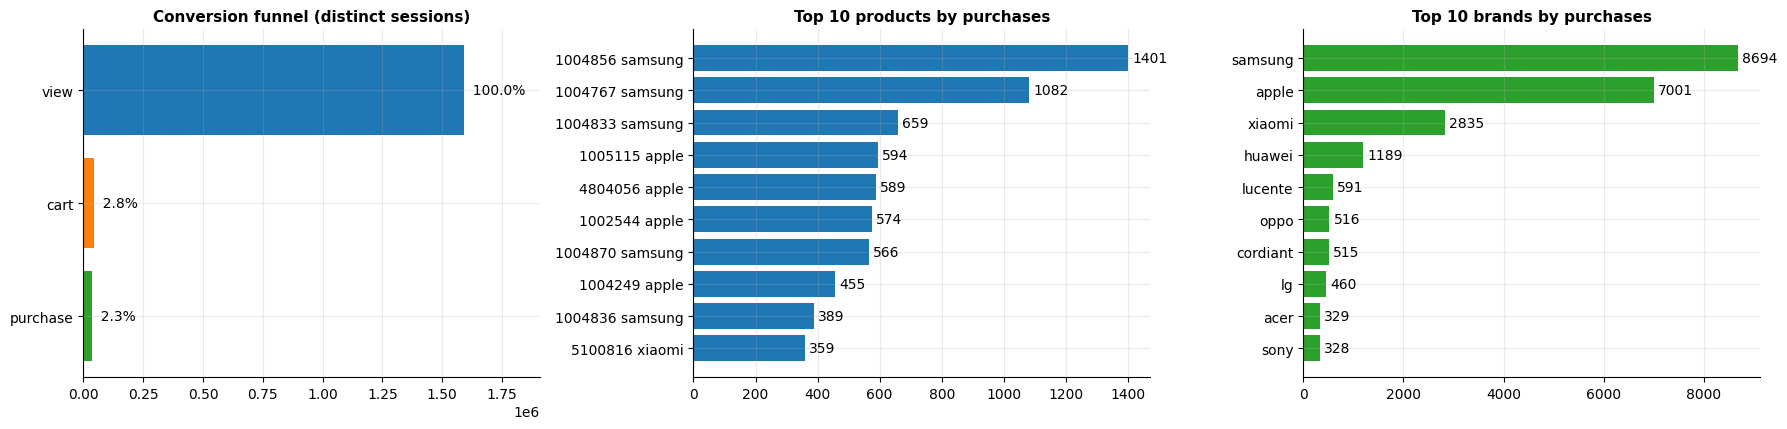

In [6]:
# ---- Spark SQL analytics ----
clean.createOrReplaceTempView("events")
size = spark.sql('''SELECT COUNT(DISTINCT user_id) users, COUNT(DISTINCT product_id) products, COUNT(DISTINCT user_session) sessions,
                           COUNT(DISTINCT category_code) categories, COUNT(DISTINCT brand) brands FROM events''').toPandas()
print(size.to_string(index=False)); R["dataset_size"] = size.iloc[0].to_dict()

funnel = (spark.sql("SELECT event_type, COUNT(DISTINCT user_session) sessions FROM events GROUP BY event_type")
          .toPandas().set_index("event_type").reindex(["view", "cart", "purchase"]))
funnel["pct"] = 100 * funnel["sessions"] / funnel.loc["view", "sessions"]; R["funnel_pct"] = funnel["pct"].round(2).to_dict()
top_prod = spark.sql('''SELECT product_id, brand, COUNT(*) purchases FROM events WHERE event_type='purchase'
                        GROUP BY 1, 2 ORDER BY purchases DESC LIMIT 10''').toPandas()
top_brand = spark.sql('''SELECT brand, COUNT(*) purchases FROM events WHERE event_type='purchase' AND brand != 'unknown'
                         GROUP BY brand ORDER BY purchases DESC LIMIT 10''').toPandas()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
ax[0].barh(funnel.index[::-1], funnel["sessions"][::-1], color=[GREEN, ORANGE, BLUE])
for k, (idx, r) in enumerate(funnel[::-1].iterrows()): ax[0].text(r["sessions"], k, f"  {r['pct']:.1f}%", va="center")
ax[0].set_title("Conversion funnel (distinct sessions)"); ax[0].set_xlim(0, funnel["sessions"].max() * 1.2)
ax[1].barh((top_prod["product_id"].astype(str) + " " + top_prod["brand"])[::-1], top_prod["purchases"][::-1], color=BLUE)
ax[1].bar_label(ax[1].containers[0], padding=3); ax[1].set_title("Top 10 products by purchases")
ax[2].barh(top_brand["brand"][::-1], top_brand["purchases"][::-1], color=GREEN)
ax[2].bar_label(ax[2].containers[0], padding=3); ax[2].set_title("Top 10 brands by purchases")
save("03_sql_funnel_top")

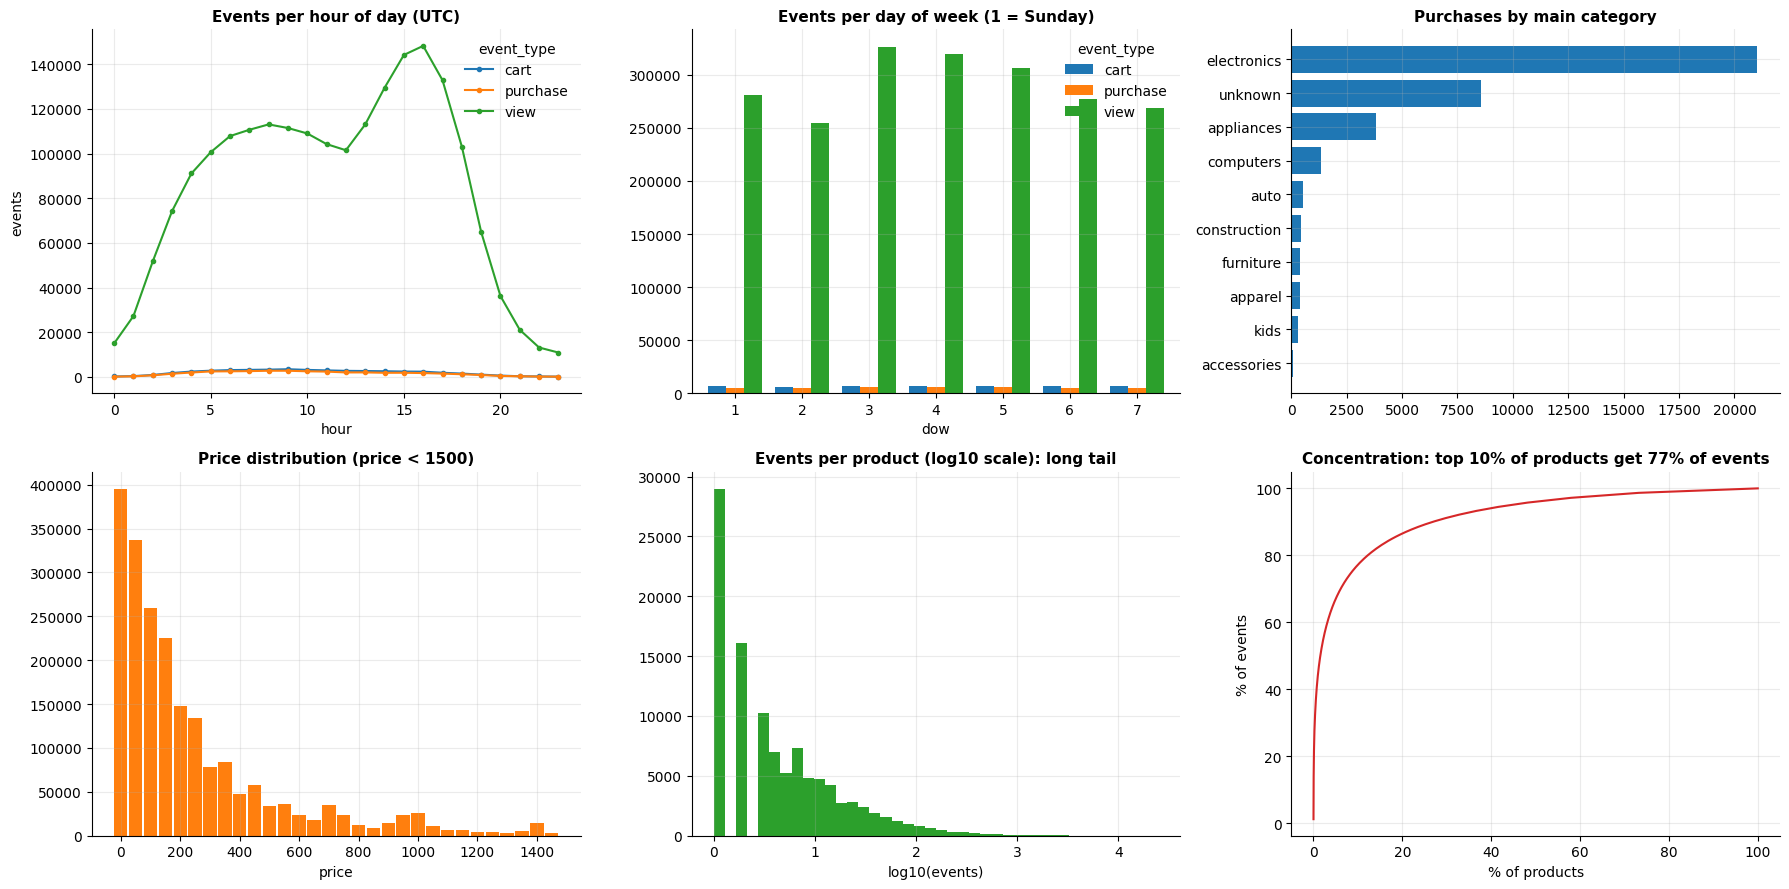

In [7]:
# ---- exploratory data analysis ----
hourly = clean.groupBy("hour", "event_type").count().toPandas().pivot(index="hour", columns="event_type", values="count")
dow = clean.groupBy("dow", "event_type").count().toPandas().pivot(index="dow", columns="event_type", values="count")
top_cat = clean.filter("event_type='purchase'").groupBy("main_category").count().orderBy(F.desc("count")).limit(10).toPandas()
price_bins = (clean.filter("price < 1500").select((F.floor(F.col("price") / 50) * 50).alias("b")).groupBy("b").count().orderBy("b").toPandas())
per_prod = np.sort(clean.groupBy("product_id").count().toPandas()["count"].to_numpy())[::-1]
share = np.cumsum(per_prod) / per_prod.sum(); top10 = float(share[max(0, int(0.1 * len(share)) - 1)]); R["top10pct_share"] = top10

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
hourly.plot(ax=ax[0, 0], marker="o", ms=3); ax[0, 0].set_title("Events per hour of day (UTC)"); ax[0, 0].set_ylabel("events")
dow.plot.bar(ax=ax[0, 1], rot=0, width=0.8); ax[0, 1].set_title("Events per day of week (1 = Sunday)")
ax[0, 2].barh(top_cat["main_category"][::-1], top_cat["count"][::-1], color=BLUE); ax[0, 2].set_title("Purchases by main category")
ax[1, 0].bar(price_bins["b"], price_bins["count"], width=45, color=ORANGE); ax[1, 0].set_title("Price distribution (price < 1500)"); ax[1, 0].set_xlabel("price")
ax[1, 1].hist(np.log10(per_prod), bins=40, color=GREEN); ax[1, 1].set_title("Events per product (log10 scale): long tail"); ax[1, 1].set_xlabel("log10(events)")
ax[1, 2].plot(np.arange(1, len(share) + 1) / len(share) * 100, share * 100, color=RED)
ax[1, 2].set_title(f"Concentration: top 10% of products get {100 * top10:.0f}% of events"); ax[1, 2].set_xlabel("% of products"); ax[1, 2].set_ylabel("% of events")
save("04_eda")

**What the figures tell us.** Very few sessions end in a purchase, and a small share of products receives most interactions (long tail). These facts matter later: they explain why a **popularity baseline is hard to beat** and why **new items are hard to recommend** (cold start).

## 5. Distributed processing in Spark

* **Transformations** (`filter`, `groupBy`, `join`) are *lazy*: they only build a plan. **Actions** (`count`, `show`, `write`, `collect`) run it.
* Spark turns the plan into a **DAG of stages**; a new stage starts at every **shuffle** (`Exchange` in the plan).
* **Caching** keeps a reused DataFrame in memory so it is not recomputed.

The code runs three small experiments: the same aggregation with the **RDD API vs the DataFrame API** (the DataFrame plan is optimised by Catalyst and Tungsten), **lazy vs action** timing, and **three repeated actions without and with cache**. A short warm-up run comes first so that one-time JVM start-up cost does not distort the timings. Open the Spark UI printed in Section 2 (*SQL* and *Stages* tabs) and take a screenshot of the DAG for the report.

define: 0.020s (no job) | execute: 0.76s | shuffles in plan: 4
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   *(3) Sort [revenue#3937 DESC NULLS LAST], true, 0
   +- AQEShuffleRead coalesced
      +- ShuffleQueryStage 1
         +- Exchange rangepartitioning(revenue#3937 DESC NULLS LAST, 64), ENSURE_REQUIREMENTS, [plan_id=1495]
            +- *(2) HashAggregate(keys=[category_code#63], functions=[count(1), sum(price#65)])
               +- AQEShuffleRead coalesced
                  +- ShuffleQueryStage 0
                     +- Exchange hashpartitioning(category_code#63, 64), ENSURE_REQUIREMENTS, [plan_id=1463]
                        +- *(1) HashAggregate(keys=[category_code#63], functions=[partial_count(1), partial_sum(price#65)])
                           +- *(1) Project [category_code#63, price#65]
                              +- *(1) Filter (isnotnull(event_type#60) AND (event_type#60 = purchase))
                                 +- *(1) ColumnarTo

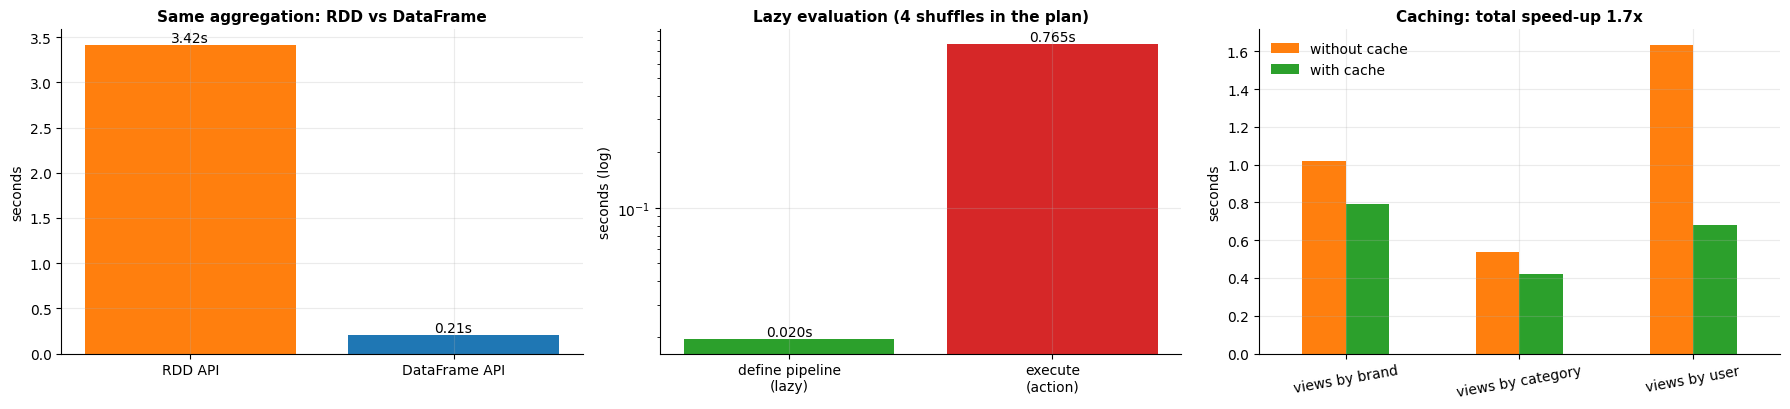

In [8]:
events_raw.count()                                                    # warm-up (JVM + file cache)

# 1) RDD vs DataFrame: count events by type
rdd = events_raw.select("event_type").rdd.map(lambda r: (r[0], 1))
_, t_rdd = timeit(lambda: rdd.reduceByKey(lambda a, b: a + b).collect())
_, t_df = timeit(lambda: events_raw.groupBy("event_type").count().collect())
R["rdd_s"], R["df_s"] = round(t_rdd, 2), round(t_df, 2)

# 2) lazy vs action
t0 = time.time()
pipeline = (events_raw.filter("event_type = 'purchase'").groupBy("category_code")
            .agg(F.count("*").alias("purchases"), F.sum("price").alias("revenue")).orderBy(F.desc("revenue")))
t_define = time.time() - t0
_, t_exec = timeit(lambda: pipeline.collect())
try: n_exchange = pipeline._jdf.queryExecution().executedPlan().toString().count("Exchange")
except Exception: n_exchange = None
print(f"define: {t_define:.3f}s (no job) | execute: {t_exec:.2f}s | shuffles in plan: {n_exchange}")
pipeline.explain()

# 3) caching: three different actions on the same filtered data
views = events_raw.filter("event_type = 'view'")
actions = {"views by brand": lambda d: d.groupBy("brand").count().count(),
           "views by category": lambda d: d.groupBy("category_code").count().count(),
           "views by user": lambda d: d.groupBy("user_id").count().count()}
t_no = {k: timeit(lambda f=f: f(views))[1] for k, f in actions.items()}
cached = views.cache(); cached.count()
t_ca = {k: timeit(lambda f=f: f(cached))[1] for k, f in actions.items()}
cached.unpersist()
speedup = sum(t_no.values()) / max(sum(t_ca.values()), 1e-9); R["cache_speedup"] = round(speedup, 2)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
ax[0].bar(["RDD API", "DataFrame API"], [t_rdd, t_df], color=[ORANGE, BLUE]); ax[0].bar_label(ax[0].containers[0], fmt="%.2fs")
ax[0].set_title("Same aggregation: RDD vs DataFrame"); ax[0].set_ylabel("seconds")
ax[1].bar(["define pipeline\n(lazy)", "execute\n(action)"], [t_define, t_exec], color=[GREEN, RED]); ax[1].set_yscale("log")
ax[1].bar_label(ax[1].containers[0], fmt="%.3fs"); ax[1].set_title(f"Lazy evaluation ({n_exchange} shuffles in the plan)"); ax[1].set_ylabel("seconds (log)")
pd.DataFrame({"without cache": t_no, "with cache": t_ca}).plot.bar(ax=ax[2], rot=10, color=[ORANGE, GREEN]); ax[2].set_ylabel("seconds")
ax[2].set_title(f"Caching: total speed-up {speedup:.1f}x")
save("05_spark_concepts")

## 6. Product similarity: shingling, MinHash and LSH

Comparing every pair of products is far too expensive. Three techniques work together:

* **Shingling:** turn a product's text into a *set* of short pieces (character or word n-grams).
* **Jaccard similarity:** `J(A,B) = |A ∩ B| / |A ∪ B|`, the overlap of two sets.
* **MinHash:** compress each set into a short *signature*; the share of equal positions in two signatures estimates `J`.
* **LSH (locality-sensitive hashing):** split signatures into bands; products that match in at least one band become *candidate pairs*, so most pairs are never compared.

### 6.1 One text document per product
The dataset has no product descriptions, so each product gets a short text such as `electronics smartphone samsung price_mid` (category path + brand + price band). **Note:** many products share exactly the same text, so the figure on the right shows how many *distinct* documents there are. This limits how fine-grained the content-based similarity can be.

+----------+----------------------------------------+-----+---------+
|product_id|doc                                     |views|purchases|
+----------+----------------------------------------+-----+---------+
|1002542   |electronics smartphone apple price_vhigh|403  |9        |
|1002923   |electronics smartphone huawei price_high|155  |3        |
|1003750   |electronics smartphone sony price_high  |90   |1        |
|1004143   |electronics smartphone xiaomi price_high|126  |4        |
|1004174   |electronics smartphone tp-link price_mid|124  |6        |
+----------+----------------------------------------+-----+---------+
only showing top 5 rows



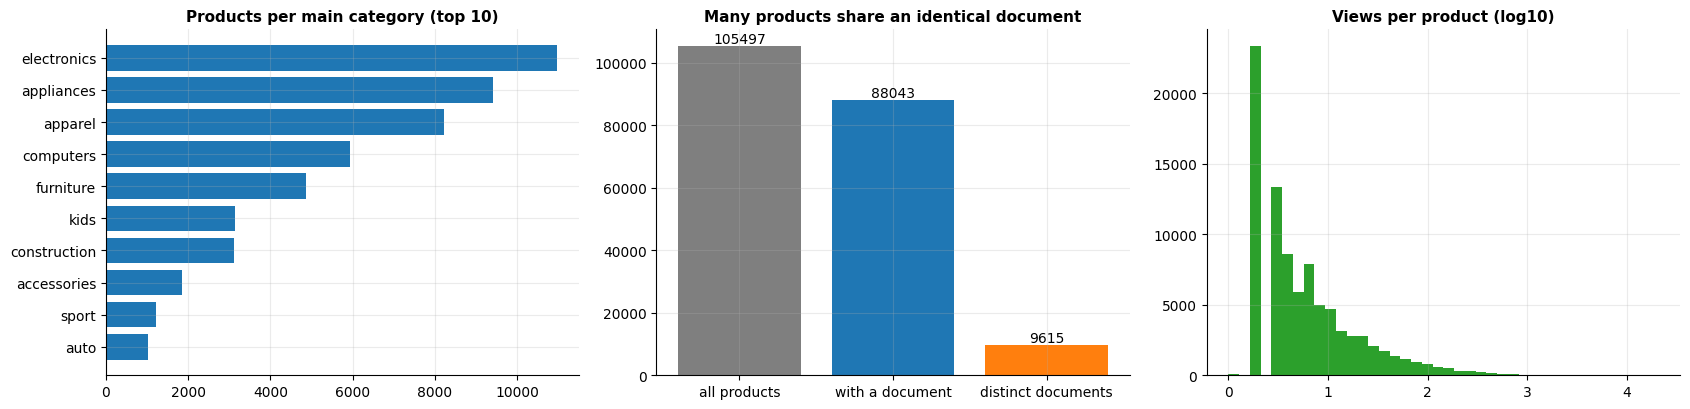

In [9]:
prod = (clean.groupBy("product_id")
        .agg(F.first("category_code").alias("category_code"), F.first("brand").alias("brand"),
             F.expr("percentile_approx(price, 0.5)").alias("price"),
             F.sum((F.col("event_type") == "view").cast("int")).alias("views"),
             F.sum((F.col("event_type") == "purchase").cast("int")).alias("purchases")))
q = prod.approxQuantile("price", [0.2, 0.4, 0.6, 0.8], 0.01)
band = (F.when(F.col("price") <= q[0], "price_vlow").when(F.col("price") <= q[1], "price_low").when(F.col("price") <= q[2], "price_mid")
         .when(F.col("price") <= q[3], "price_high").otherwise("price_vhigh"))
prod_doc = (prod.withColumn("price_band", band)
            .withColumn("doc", F.concat_ws(" ", F.regexp_replace("category_code", r"[\._]", " "), F.col("brand"), F.col("price_band")))
            .filter("category_code != 'unknown' OR brand != 'unknown'").cache())
n_prod, n_doc = prod.count(), prod_doc.count(); n_unique = prod_doc.select("doc").distinct().count()
R["products"] = {"all": n_prod, "with_document": n_doc, "unique_documents": n_unique}
prod_doc.select("product_id", "doc", "views", "purchases").show(5, truncate=False)

cats = (prod_doc.withColumn("main", F.split("category_code", r"\.").getItem(0)).filter("main != 'unknown'")
        .groupBy("main").count().orderBy(F.desc("count")).limit(10).toPandas())
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].barh(cats["main"][::-1], cats["count"][::-1], color=BLUE); ax[0].set_title("Products per main category (top 10)")
ax[1].bar(["all products", "with a document", "distinct documents"], [n_prod, n_doc, n_unique], color=[GREY, BLUE, ORANGE])
ax[1].bar_label(ax[1].containers[0], fmt="%d"); ax[1].set_title("Many products share an identical document")
ax[2].hist(np.log10(prod_doc.select("views").toPandas()["views"] + 1), bins=40, color=GREEN); ax[2].set_title("Views per product (log10)")
save("06a_product_documents")

### 6.2 MinHash from scratch (small sample)
To show how MinHash works, we build signatures **by hand** for 2,000 products. Each hash function is `h(x) = (a·x + b) mod p`; a signature entry is the *minimum* hash over the shingles of a product. We then compare the signature-based estimate with the **exact** Jaccard similarity on 300 random pairs.

* Left: the error shrinks as the signature gets longer (about `1/√n`).
* Middle: with 256 hashes the estimates lie on the diagonal (perfect agreement), with 16 they scatter.
* Right: **LSH banding.** With `b` bands of `r` rows, a pair with similarity `s` becomes a candidate with probability `1 − (1 − s^r)^b`. This S-curve is what makes LSH select similar pairs and ignore dissimilar ones.

distinct shingles: 2255 | MAE by signature length: {16: 0.0727, 32: 0.0454, 64: 0.0348, 128: 0.0215, 256: 0.0144}


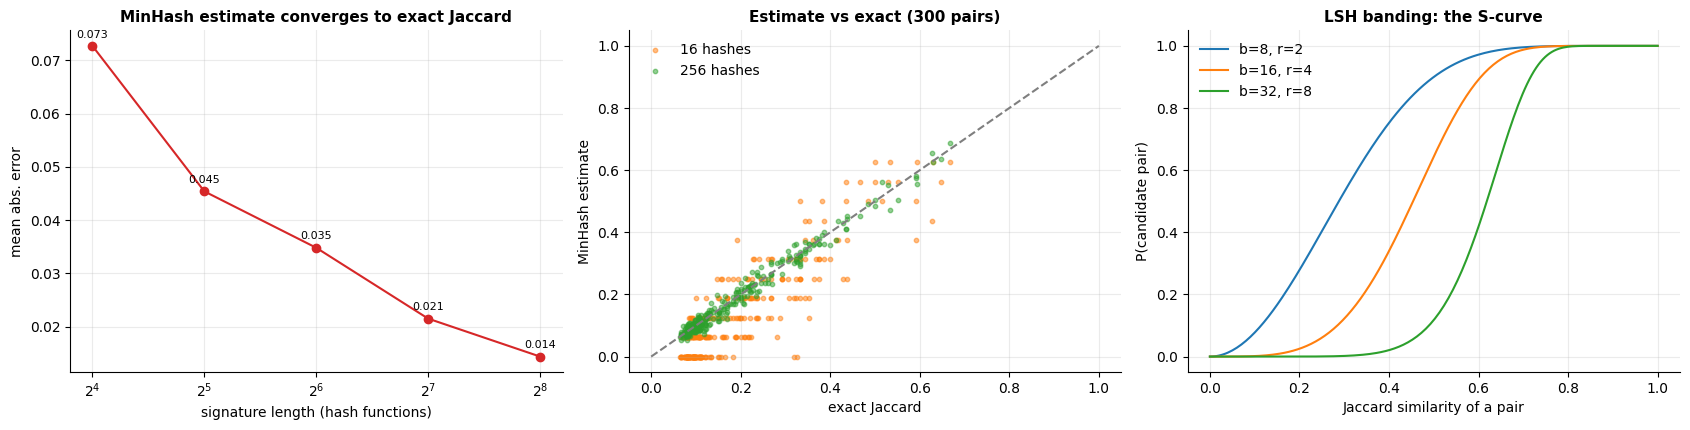

In [10]:
PRIME = (1 << 31) - 1
def shingles(text, k=3):                      # character k-shingles of every word, ^ and $ mark word boundaries
    s = set()
    for t in text.lower().split():
        t = f"^{t}$"; s.update(t[i:i + k] for i in range(max(1, len(t) - k + 1)))
    return s

docs = prod_doc.select("doc").limit(2000).toPandas()["doc"].tolist()
sets = [shingles(d) for d in docs]; vocab = {sh: i for i, sh in enumerate(set().union(*sets))}
pairs = [tuple(random.sample(range(len(sets)), 2)) for _ in range(300)]
exact = np.array([len(sets[i] & sets[j]) / len(sets[i] | sets[j]) for i, j in pairs])

mae, est = {}, {}
for n_hash in (16, 32, 64, 128, 256):
    rng = np.random.RandomState(RANDOM_SEED); a, b = rng.randint(1, PRIME, n_hash), rng.randint(0, PRIME, n_hash)
    sig = np.empty((n_hash, len(sets)), dtype=np.int64)
    for j, s in enumerate(sets):                                    # signature = min over shingles of (a*x + b) mod p
        idx = np.fromiter((vocab[x] for x in s), dtype=np.int64)
        sig[:, j] = ((a[:, None] * idx[None, :] + b[:, None]) % PRIME).min(axis=1)
    est[n_hash] = np.array([(sig[:, i] == sig[:, j]).mean() for i, j in pairs]); mae[n_hash] = float(np.abs(est[n_hash] - exact).mean())
R["minhash_mae"] = {k: round(v, 4) for k, v in mae.items()}; print("distinct shingles:", len(vocab), "| MAE by signature length:", R["minhash_mae"])

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].plot(list(mae), list(mae.values()), marker="o", color=RED); ax[0].set_xscale("log", base=2)
for x_, y_ in mae.items(): ax[0].annotate(f"{y_:.3f}", (x_, y_), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8)
ax[0].set_xlabel("signature length (hash functions)"); ax[0].set_ylabel("mean abs. error"); ax[0].set_title("MinHash estimate converges to exact Jaccard")
for n_hash, col in [(16, ORANGE), (256, GREEN)]: ax[1].scatter(exact, est[n_hash], s=10, alpha=0.5, color=col, label=f"{n_hash} hashes")
ax[1].plot([0, 1], [0, 1], "--", color=GREY); ax[1].set_xlabel("exact Jaccard"); ax[1].set_ylabel("MinHash estimate"); ax[1].legend(); ax[1].set_title("Estimate vs exact (300 pairs)")
s = np.linspace(0, 1, 200)
for bands, rows, col in [(8, 2, BLUE), (16, 4, ORANGE), (32, 8, GREEN)]: ax[2].plot(s, 1 - (1 - s ** rows) ** bands, label=f"b={bands}, r={rows}", color=col)
ax[2].set_xlabel("Jaccard similarity of a pair"); ax[2].set_ylabel("P(candidate pair)"); ax[2].legend(); ax[2].set_title("LSH banding: the S-curve")
save("06b_minhash_lsh_theory")

### 6.3 LSH in PySpark
The Spark ML pipeline is: **tokenise → word unigrams + bigrams (word-level shingles) → binary count vectors → `MinHashLSH`** with 8 hash tables. It supports two operations:

* **nearest neighbours** of one product (*alternative products*),
* a **similarity join** (near-duplicate detection, used in Section 9).

The cell also shows the **cold-start advantage**: a *brand-new* product is vectorised and hashed with the already fitted models, and its neighbours are found in milliseconds, with **no retraining**.

vectors: 88043 | vocabulary size: 14571
most viewed product: electronics smartphone samsung price_high
 product_id                                       doc  dist
    1004168 electronics smartphone samsung price_high   0.0
    1003911 electronics smartphone samsung price_high   0.0
    1004750 electronics smartphone samsung price_high   0.0
    1003861 electronics smartphone samsung price_high   0.0
    1005212 electronics smartphone samsung price_high   0.0
    1004833 electronics smartphone samsung price_high   0.0
    1003913 electronics smartphone samsung price_high   0.0
    1005211 electronics smartphone samsung price_high   0.0
lookup time for a new product: 229 ms


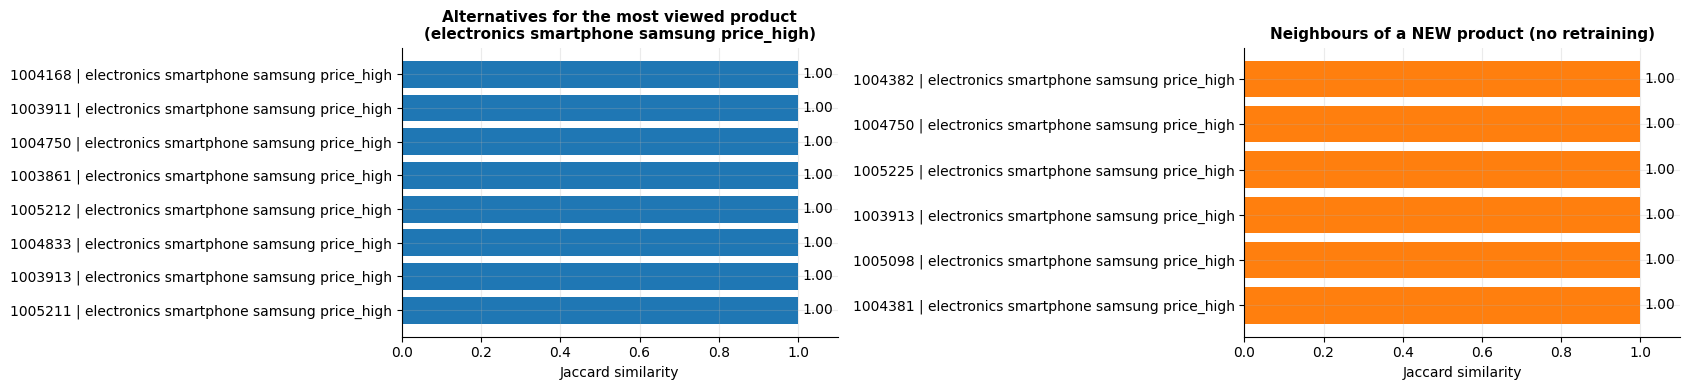

In [11]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Tokenizer, NGram, CountVectorizer, MinHashLSH, SQLTransformer

feat_pipe = Pipeline(stages=[Tokenizer(inputCol="doc", outputCol="words"), NGram(n=2, inputCol="words", outputCol="bigrams"),
                             SQLTransformer(statement="SELECT *, concat(words, bigrams) AS shingles FROM __THIS__"),
                             CountVectorizer(inputCol="shingles", outputCol="features", binary=True, minDF=1, vocabSize=1 << 16)]).fit(prod_doc)
prod_vec = feat_pipe.transform(prod_doc).select("product_id", "doc", "category_code", "brand", "price", "views", "features").cache()
lsh = MinHashLSH(inputCol="features", outputCol="hashes", numHashTables=8, seed=RANDOM_SEED).fit(prod_vec)
prod_hash = lsh.transform(prod_vec).cache()
print("vectors:", prod_hash.count(), "| vocabulary size:", len(feat_pipe.stages[-1].vocabulary))

def nearest(vec, k):                                       # k nearest products by Jaccard distance (via LSH)
    return (lsh.approxNearestNeighbors(prod_vec, vec, k).select("product_id", "doc", F.round("distCol", 3).alias("dist")).toPandas())

one = prod_doc.orderBy(F.desc("views")).first()
alt = nearest(prod_vec.filter(F.col("product_id") == one["product_id"]).first()["features"], 8)
new_doc = "electronics smartphone samsung price_high"                      # a product that is not in the data
new_vec = feat_pipe.transform(spark.createDataFrame([(new_doc,)], ["doc"])).first()["features"]
(new_match, t_new) = timeit(lambda: nearest(new_vec, 6)); R["new_product_lookup_ms"] = round(t_new * 1000)
print("most viewed product:", one["doc"]); print(alt.to_string(index=False)); print(f"lookup time for a new product: {t_new * 1000:.0f} ms")

fig, ax = plt.subplots(1, 2, figsize=(17, 4))
for a_, d_, ttl, col in [(ax[0], alt, f"Alternatives for the most viewed product\n({one['doc']})", BLUE), (ax[1], new_match, "Neighbours of a NEW product (no retraining)", ORANGE)]:
    a_.barh((d_["product_id"].astype(str) + " | " + d_["doc"])[::-1], (1 - d_["dist"])[::-1], color=col); a_.set_xlim(0, 1.1)
    a_.bar_label(a_.containers[0], fmt="%.2f", padding=3); a_.set_xlabel("Jaccard similarity"); a_.set_title(ttl)
save("06c_alternatives_new_product")

### 6.4 How good is the similarity?
There are no human labels, so *expected similar* is defined as **same leaf category**. We measure:

* **Precision@10** of the LSH neighbours against a **random baseline** (the chance that two random products share a category),
* **recall of LSH against exact brute-force Jaccard** on a small sample, for 1, 2, 4 and 8 hash tables (more tables = more candidate pairs = higher recall).

> **Honest note.** The product text contains the category, so same-category agreement is partly *by construction*. It still checks that the hashing retrieves what the text says is similar. Real product titles with human labels would be a stronger test.

LSH Precision@10: 0.995 | random: 0.1956 | exact close pairs: 966 | recall by tables: {1: 1.0, 2: 1.0, 4: 1.0, 8: 1.0}


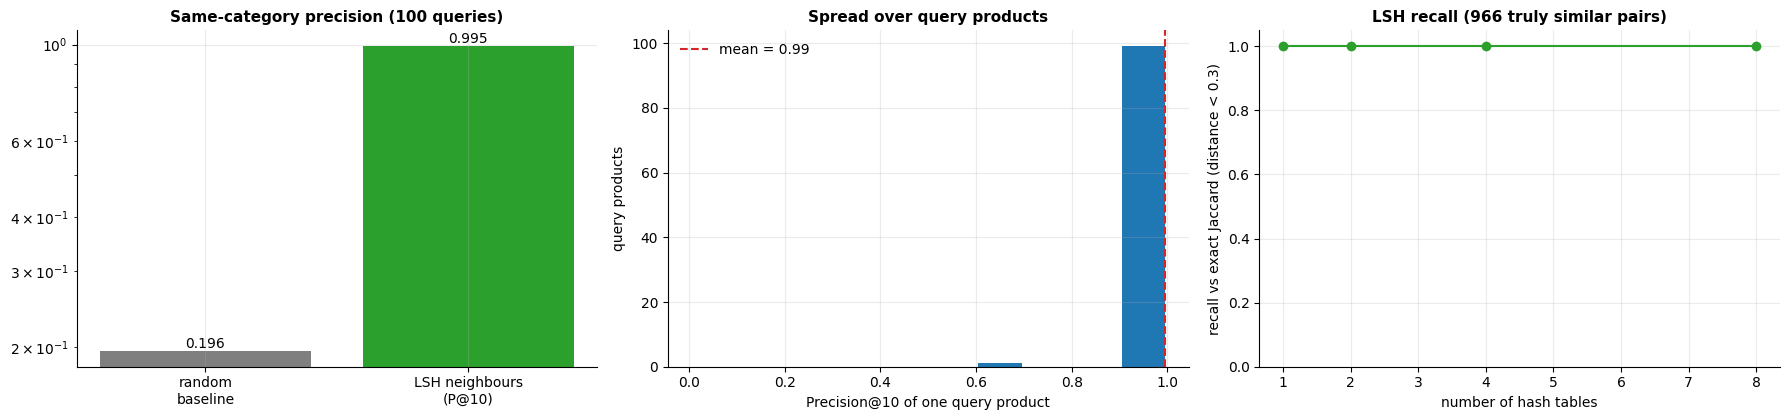

In [12]:
from pyspark.sql.functions import udf
K = 10
queries = prod_vec.filter("category_code != 'unknown'").orderBy(F.rand(RANDOM_SEED)).limit(N_SIM_QUERIES).collect()
p_each = []
for qr in queries:
    nn = (lsh.approxNearestNeighbors(prod_vec, qr["features"], K + 1).filter(F.col("product_id") != qr["product_id"]).select("category_code").collect())
    if nn: p_each.append(np.mean([r[0] == qr["category_code"] for r in nn]))
p_each = np.array(p_each); p_at_k = float(p_each.mean())
cnt = prod_vec.groupBy("category_code").count().toPandas()["count"]; rand_base = float(((cnt / cnt.sum()) ** 2).sum())

# exact brute force on a small sample: every pair, exact Jaccard distance
jdist = udf(lambda u, v: float(1 - len(set(u.indices) & set(v.indices)) / max(1, len(set(u.indices) | set(v.indices)))), T.DoubleType())
small = prod_vec.limit(N_RECALL_SAMPLE).cache(); small.count()
n_exact = (small.alias("a").crossJoin(small.alias("b")).filter("a.product_id < b.product_id")
           .withColumn("jd", jdist(F.col("a.features"), F.col("b.features"))).filter(F.col("jd") < 0.3).count())
recall = {}
for tables in (1, 2, 4, 8):                                # LSH pairs are verified with the exact distance, so recall = found / exact
    m = MinHashLSH(inputCol="features", outputCol="hashes", numHashTables=tables, seed=RANDOM_SEED).fit(small)
    found = m.approxSimilarityJoin(small, small, 0.3).filter(F.col("datasetA.product_id") < F.col("datasetB.product_id")).count()
    recall[tables] = found / max(n_exact, 1)
R["similarity"] = {"p_at_10": round(p_at_k, 4), "random_baseline": round(rand_base, 6)}; R["lsh_recall"] = {k: round(v, 3) for k, v in recall.items()}
print(f"LSH Precision@{K}: {p_at_k:.3f} | random: {rand_base:.4f} | exact close pairs: {n_exact:,} | recall by tables: {R['lsh_recall']}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
ax[0].bar(["random\nbaseline", f"LSH neighbours\n(P@{K})"], [rand_base, p_at_k], color=[GREY, GREEN]); ax[0].set_yscale("log"); ax[0].bar_label(ax[0].containers[0], fmt="%.3f")
ax[0].set_title(f"Same-category precision ({len(p_each)} queries)")
ax[1].hist(p_each, bins=np.linspace(0, 1, 11), color=BLUE, rwidth=0.9); ax[1].axvline(p_at_k, color=RED, ls="--", label=f"mean = {p_at_k:.2f}"); ax[1].legend()
ax[1].set_xlabel(f"Precision@{K} of one query product"); ax[1].set_ylabel("query products"); ax[1].set_title("Spread over query products")
ax[2].plot(list(recall), list(recall.values()), marker="o", color=GREEN); ax[2].set_ylim(0, 1.05); ax[2].set_xlabel("number of hash tables")
ax[2].set_ylabel("recall vs exact Jaccard (distance < 0.3)"); ax[2].set_title(f"LSH recall ({n_exact:,} truly similar pairs)")
save("06d_similarity_quality")

## 7. Recommendation model: ALS

**Collaborative filtering** recommends items liked by similar users. **Matrix factorisation** approximates the sparse user-item matrix by two small matrices of *latent factors*. **ALS (Alternating Least Squares)** solves for the user factors while the item factors are fixed, then the other way round; every row is independent, so it runs in parallel on Spark.

| Version | Target | Metric |
|---|---|---|
| Implicit ALS | confidence from interaction strength | **Precision@K, Recall@K, Hit rate@K** (ranking quality) |
| Explicit ALS | derived rating 1 / 3 / 5 | **RMSE** (secondary check) |

The data has no star ratings, so ranking metrics on *future* purchases are the meaningful measure.

### 7.1 Time-based split and the user-item matrix
We split **by time**, not randomly (a random split lets the model see the future): oldest 70% = train, next 15% = validation, last 15% = test. An item is **relevant** for a user if the user carted or purchased it in the evaluation period. Users and items with fewer than 3 interactions are dropped from training (too little signal). Items a user already knew are removed from that user's recommendations.

The figures show the interactions over time, how many interactions each user has, and how many each item has. The matrix is **extremely sparse**, which makes this problem hard.

validation starts 2019-10-22 08:57:31 | test starts 2019-10-26 19:49:51
train matrix: 136,433 users x 46,339 items, 619,896 non-zeros, density = 9.81e-05


validation users with relevant items: 1944 | relevant pairs: 2132


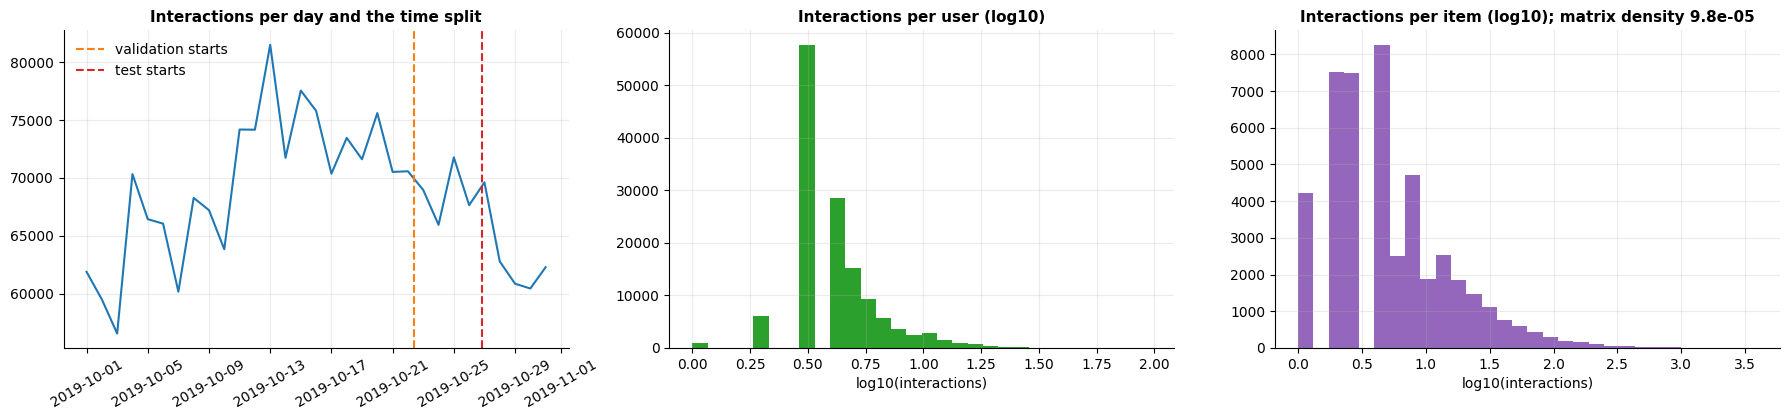

In [13]:
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

W = F.when(F.col("event_type") == "view", 1.0).when(F.col("event_type") == "cart", 3.0).otherwise(5.0)     # implicit rating
MAXI = 2 ** 31 - 1                                                                                          # ALS needs int ids
inter = (clean.filter((F.col("user_id") <= MAXI) & (F.col("product_id") <= MAXI))
         .select(F.col("user_id").cast("int").alias("u"), F.col("product_id").cast("int").alias("i"), W.alias("w"),
                 F.unix_timestamp("event_time").alias("t"))).cache()

def to_matrix(df):                      # one row per (user, item): rating = strongest action, strength = sum of weights, conf = log(1 + strength)
    return df.groupBy("u", "i").agg(F.max("w").alias("rating"), F.sum("w").alias("strength")).withColumn("conf", F.log1p("strength"))

def min_activity(m, k=3):               # keep users and items with at least k interactions
    gu = m.groupBy("u").count().filter(F.col("count") >= k).select("u"); gi = m.groupBy("i").count().filter(F.col("count") >= k).select("i")
    return m.join(gu, "u", "left_semi").join(gi, "i", "left_semi")

def truth_of(ev, users, items):         # relevant = carted or purchased in the period, for users/items known from training
    return ev.filter("w >= 3").select("u", "i").distinct().join(users, "u", "left_semi").join(items, "i", "left_semi")

t_valid, t_test = inter.approxQuantile("t", [0.70, 0.85], 0.001)
train_ev = inter.filter(F.col("t") < t_valid); valid_ev = inter.filter((F.col("t") >= t_valid) & (F.col("t") < t_test)); test_ev = inter.filter(F.col("t") >= t_test)
tr = min_activity(to_matrix(train_ev)).cache()
users_tr, items_tr = tr.select("u").distinct().cache(), tr.select("i").distinct().cache()
n_ui, n_u, n_i = tr.count(), users_tr.count(), items_tr.count(); density = n_ui / (n_u * n_i)
R["als_matrix"] = {"users": n_u, "items": n_i, "nonzeros": n_ui, "density": density}
print(f"validation starts {pd.to_datetime(t_valid, unit='s')} | test starts {pd.to_datetime(t_test, unit='s')}")
print(f"train matrix: {n_u:,} users x {n_i:,} items, {n_ui:,} non-zeros, density = {density:.2e}")

truth_v = truth_of(valid_ev, users_tr, items_tr)
eval_users_v = truth_v.select("u").distinct().orderBy(F.rand(RANDOM_SEED)).limit(N_EVAL_USERS).cache()
truth_v = truth_v.join(eval_users_v, "u", "left_semi").cache()
print("validation users with relevant items:", eval_users_v.count(), "| relevant pairs:", truth_v.count())

daily_i = inter.withColumn("d", F.to_date(F.from_unixtime("t"))).groupBy("d").count().orderBy("d").toPandas()
upi = tr.groupBy("u").count().toPandas()["count"].to_numpy(); ipi = tr.groupBy("i").count().toPandas()["count"].to_numpy()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
ax[0].plot(daily_i["d"], daily_i["count"], color=BLUE)
for tt, lab, col in [(t_valid, "validation starts", ORANGE), (t_test, "test starts", RED)]: ax[0].axvline(pd.to_datetime(tt, unit="s"), color=col, ls="--", label=lab)
ax[0].legend(); ax[0].set_title("Interactions per day and the time split"); ax[0].tick_params(axis="x", rotation=30)
ax[1].hist(np.log10(upi), bins=30, color=GREEN); ax[1].set_title("Interactions per user (log10)"); ax[1].set_xlabel("log10(interactions)")
ax[2].hist(np.log10(ipi), bins=30, color=PURPLE); ax[2].set_title(f"Interactions per item (log10); matrix density {density:.1e}"); ax[2].set_xlabel("log10(interactions)")
save("07a_split_and_sparsity")

### 7.2 Metrics and the popularity baseline
A recommender is only useful if it beats **simply showing the most popular items**. For the first K recommendations of each user (after removing items the user already knew) we compute:

* **Precision@K** = hits / K,
* **Recall@K** = hits / number of relevant items,
* **Hit rate@K** = share of users with at least one hit.

The baseline recommends the same most-popular items to everyone.

In [14]:
def metrics_at_k(recs, seen, truth, Ks=(5, 10, 20)):
    # recs: (u, i, score). Remove seen items, rank per user, compute Precision / Recall / HitRate @K
    recs = recs.join(seen.select("u", "i"), ["u", "i"], "left_anti")
    rk = recs.withColumn("rk", F.row_number().over(Window.partitionBy("u").orderBy(F.desc("score")))).filter(F.col("rk") <= max(Ks))
    hit = rk.join(truth.withColumn("rel", F.lit(1)), ["u", "i"], "left").withColumn("rel", F.coalesce("rel", F.lit(0)))
    n_true = truth.groupBy("u").agg(F.count("*").alias("n_true")); out = {}
    for k in Ks:
        row = (hit.filter(F.col("rk") <= k).groupBy("u").agg(F.sum("rel").alias("h")).join(n_true, "u", "right").fillna(0, ["h"])
               .agg(F.avg(F.col("h") / k).alias("p"), F.avg(F.col("h") / F.col("n_true")).alias("r"), F.avg((F.col("h") > 0).cast("double")).alias("hr")).first())
        out[k] = {"precision": row["p"], "recall": row["r"], "hit_rate": row["hr"]}
    return out

def als_recs(model, users, n=300):
    return (model.recommendForUserSubset(users, n).select("u", F.explode("recommendations").alias("r"))
            .select("u", F.col("r.i").alias("i"), F.col("r.rating").alias("score")))

def popularity_recs(matrix, users, n=500):
    pop = matrix.groupBy("i").agg(F.sum("strength").alias("score")).orderBy(F.desc("score")).limit(n)
    return users.crossJoin(F.broadcast(pop))

def fit_implicit_als(matrix, rank, reg, alpha, iters):
    return ALS(userCol="u", itemCol="i", ratingCol="conf", implicitPrefs=True, rank=rank, regParam=reg, alpha=alpha, maxIter=iters,
               nonnegative=True, seed=RANDOM_SEED, numUserBlocks=20, numItemBlocks=20, coldStartStrategy="drop").fit(matrix)

base_valid = metrics_at_k(popularity_recs(tr, eval_users_v), tr, truth_v)
print("Popularity baseline (validation):", {k: {m: round(x, 4) for m, x in d.items()} for k, d in base_valid.items()})

Popularity baseline (validation): {5: {'precision': 0.0121, 'recall': 0.0533, 'hit_rate': 0.0592}, 10: {'precision': 0.0099, 'recall': 0.0883, 'hit_rate': 0.0952}, 20: {'precision': 0.0076, 'recall': 0.1359, 'hit_rate': 0.1456}}


### 7.3 Tuning
A small grid over `rank` (number of latent factors), `regParam` (regularisation) and `alpha` (confidence scaling), **chosen on the validation period only**. The figure ranks the settings by Precision@10 against the popularity baseline (red line) and shows the effect of `rank` and `regParam`. Differences between settings are usually small compared with the gap to the baseline.

 rank  regParam  alpha    P10    R10   HR10  fit_s
   20      0.01     10 0.0057 0.0520 0.0571    8.0
   50      0.10     10 0.0056 0.0507 0.0556   12.6
   20      0.10     10 0.0052 0.0472 0.0525    5.8
   20      0.01     40 0.0052 0.0487 0.0525    5.1
   20      0.10     40 0.0050 0.0471 0.0504    4.8
   50      0.01     40 0.0050 0.0458 0.0504   12.6
   50      0.10     40 0.0050 0.0449 0.0499   12.8
   50      0.01     10 0.0048 0.0437 0.0478   13.9

best: {'rank': np.float64(20.0), 'regParam': np.float64(0.01), 'alpha': np.float64(10.0)}


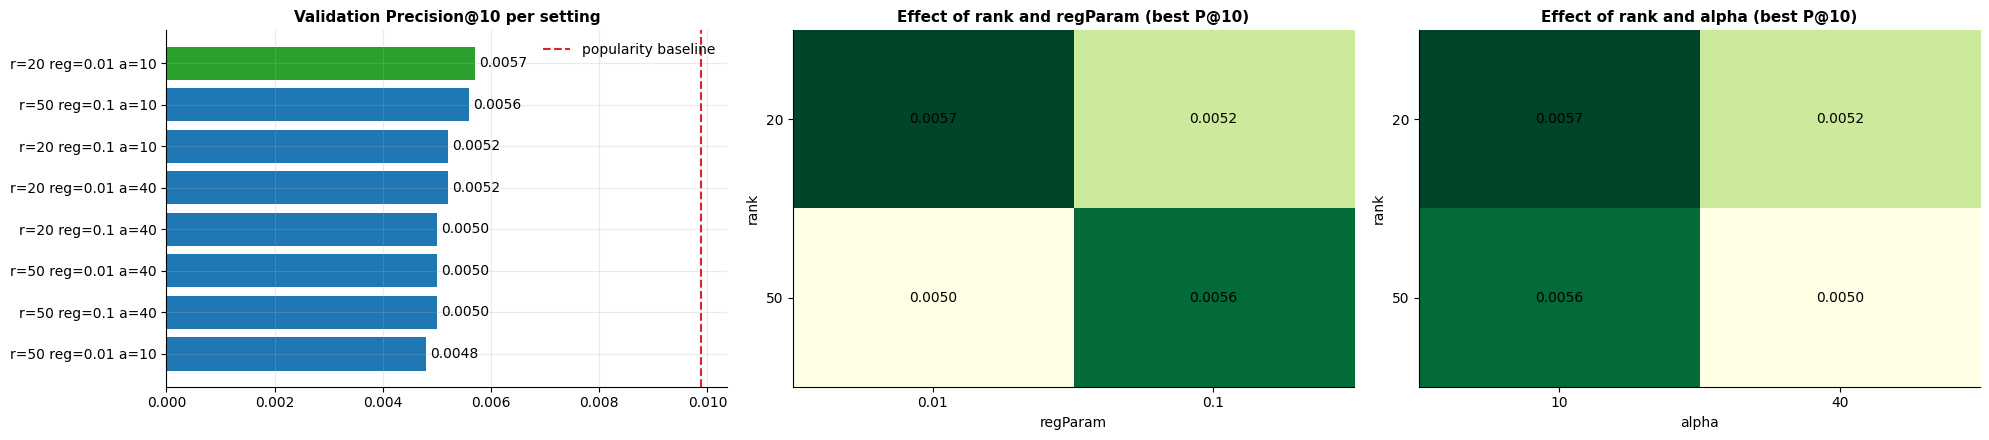

In [15]:
rows = []
for rank, reg, alpha in iproduct([20, 50], [0.01, 0.1], [10, 40]):
    (m, t_fit) = timeit(lambda: fit_implicit_als(tr, rank, reg, alpha, 10))
    met = metrics_at_k(als_recs(m, eval_users_v), tr, truth_v)[10]
    rows.append(dict(rank=rank, regParam=reg, alpha=alpha, P10=met["precision"], R10=met["recall"], HR10=met["hit_rate"], fit_s=round(t_fit, 1)))
tune = pd.DataFrame(rows).sort_values("P10", ascending=False).round(4); best = tune.iloc[0]
print(tune.to_string(index=False)); print("\nbest:", dict(best[["rank", "regParam", "alpha"]]))

fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
lab = [f"r={int(r.rank)} reg={r.regParam} a={int(r.alpha)}" for r in tune.itertuples()]
ax[0].barh(lab[::-1], tune["P10"][::-1], color=[GREEN if k == 0 else BLUE for k in range(len(tune))][::-1]); ax[0].bar_label(ax[0].containers[0], fmt="%.4f", padding=3)
ax[0].axvline(base_valid[10]["precision"], color=RED, ls="--", label="popularity baseline"); ax[0].legend(); ax[0].set_title("Validation Precision@10 per setting")
for a_, col_, ttl in [(ax[1], "regParam", "Effect of rank and regParam (best P@10)"), (ax[2], "alpha", "Effect of rank and alpha (best P@10)")]:
    piv = tune.pivot_table(index="rank", columns=col_, values="P10", aggfunc="max"); im = a_.imshow(piv.values, cmap="YlGn", aspect="auto")
    a_.set_xticks(range(len(piv.columns))); a_.set_xticklabels(piv.columns); a_.set_yticks(range(len(piv.index))); a_.set_yticklabels(piv.index)
    a_.set_xlabel(col_); a_.set_ylabel("rank"); a_.set_title(ttl); a_.grid(False)
    for (i_, j_), v_ in np.ndenumerate(piv.values): a_.text(j_, i_, f"{v_:.4f}", ha="center", va="center")
save("07b_als_tuning")

### 7.4 Final model and test results
We retrain on **train + validation** with the best settings and evaluate **once** on the untouched **test period**, for ALS and for the popularity baseline at K = 5, 10 and 20. The model is saved for later use.

**How to read the result.** If ALS does not beat popularity, report it as it is and explain why: very sparse matrix (see the density), a strong popularity effect (long tail), many new users and items in the test period (cold start, see 7.7), and a run on only a *sample* of the data (`SAMPLE_FRACTION`). Running on the **full** data usually gives ALS more signal.

         model  K  precision  recall  hit_rate
    Popularity  5     0.0151  0.0669    0.0725
    Popularity 10     0.0130  0.1154    0.1249
    Popularity 20     0.0090  0.1614    0.1738
ALS (implicit)  5     0.0120  0.0531    0.0583
ALS (implicit) 10     0.0082  0.0715    0.0807
ALS (implicit) 20     0.0058  0.1036    0.1137


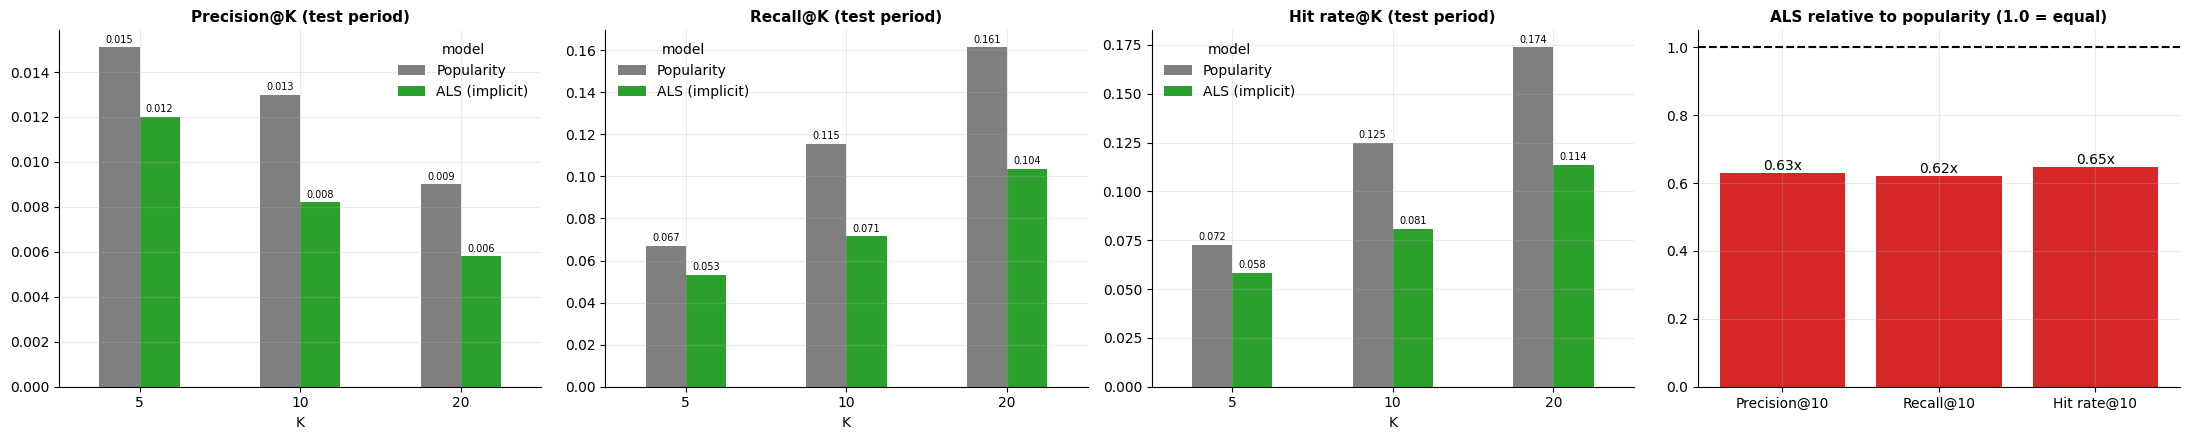

In [16]:
tr_full = min_activity(to_matrix(inter.filter(F.col("t") < t_test))).cache()
users_f, items_f = tr_full.select("u").distinct().cache(), tr_full.select("i").distinct().cache()
truth_t = truth_of(test_ev, users_f, items_f)
eval_users_t = truth_t.select("u").distinct().orderBy(F.rand(RANDOM_SEED)).limit(N_EVAL_USERS).cache()
truth_t = truth_t.join(eval_users_t, "u", "left_semi").cache()

(als_final, fit_s) = timeit(lambda: fit_implicit_als(tr_full, int(best["rank"]), float(best["regParam"]), float(best["alpha"]), 15))
als_m = metrics_at_k(als_recs(als_final, eval_users_t), tr_full, truth_t)
pop_m = metrics_at_k(popularity_recs(tr_full, eval_users_t), tr_full, truth_t)
tab = pd.DataFrame([{"model": n, "K": k, **{m_: round(v, 4) for m_, v in d.items()}} for n, mm in [("Popularity", pop_m), ("ALS (implicit)", als_m)] for k, d in mm.items()])
print(tab.to_string(index=False)); R["ranking_test"] = tab.to_dict("records"); R["als_fit_s"] = round(fit_s, 1)
als_final.write().overwrite().save(str(WORK_DIR / "models" / "als_implicit"))

fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
for a_, (metric, ttl) in zip(ax[:3], [("precision", "Precision@K"), ("recall", "Recall@K"), ("hit_rate", "Hit rate@K")]):
    tab.pivot(index="K", columns="model", values=metric)[["Popularity", "ALS (implicit)"]].plot.bar(ax=a_, rot=0, color=[GREY, GREEN])
    for c in a_.containers: a_.bar_label(c, fmt="%.3f", fontsize=7, padding=2)
    a_.set_title(f"{ttl} (test period)")
r10 = tab[tab["K"] == 10].set_index("model"); ratio = r10.loc["ALS (implicit)"] / r10.loc["Popularity"]
ax[3].bar(["Precision@10", "Recall@10", "Hit rate@10"], [ratio["precision"], ratio["recall"], ratio["hit_rate"]], color=[GREEN if x >= 1 else RED for x in ratio[["precision", "recall", "hit_rate"]]])
ax[3].axhline(1, color="black", ls="--"); ax[3].bar_label(ax[3].containers[0], fmt="%.2fx"); ax[3].set_title("ALS relative to popularity (1.0 = equal)")
save("07c_als_vs_popularity")

### 7.5 What did ALS learn? (latent space)
Each product has a vector of latent factors. If ALS has learned real structure, products of the same **main category** should land close together once the factors are projected to 2-D with **PCA** (computed with an SVD in NumPy). The right figure shows how much variance each principal component explains.

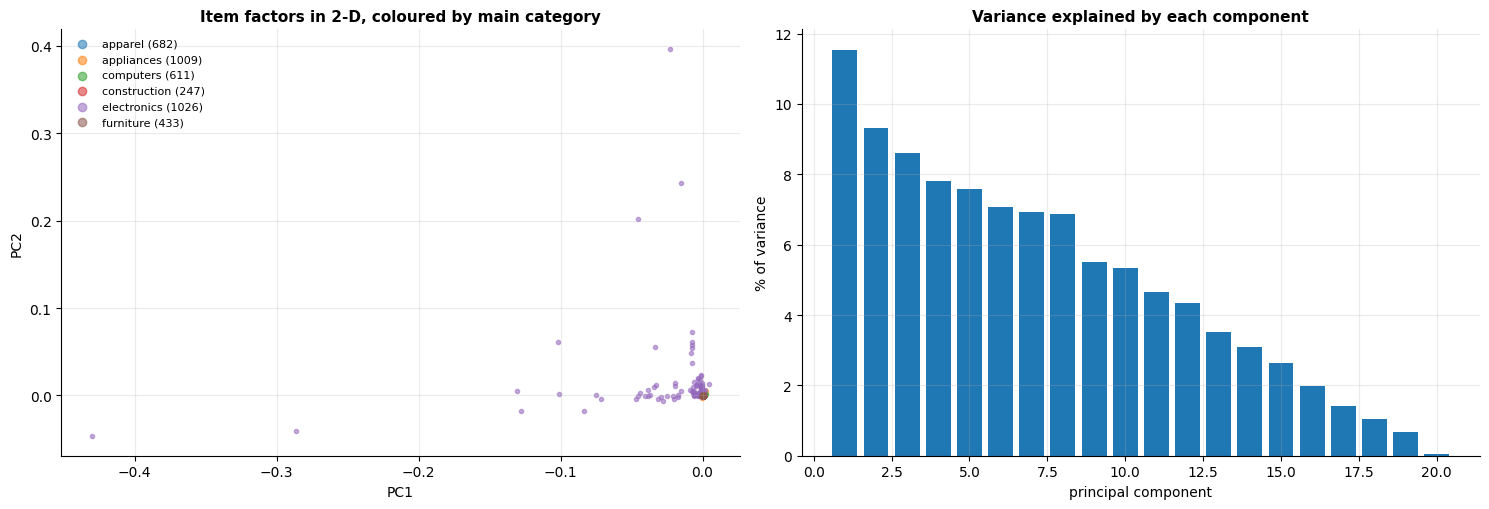

In [17]:
cat = (prod_doc.select(F.col("product_id").alias("id"), F.split("category_code", r"\.").getItem(0).alias("main_cat")).filter("main_cat != 'unknown'"))
fac = als_final.itemFactors.join(cat, "id")
top = [r[0] for r in fac.groupBy("main_cat").count().orderBy(F.desc("count")).limit(6).collect()]
fac = fac.filter(F.col("main_cat").isin(top)); total = fac.count()
pdf = fac.sample(False, min(1.0, 4000 / max(total, 1)), RANDOM_SEED).toPandas()
X = np.array(pdf["features"].tolist(), dtype=float); X -= X.mean(axis=0)
U, S, Vt = np.linalg.svd(X, full_matrices=False); pdf["pc1"], pdf["pc2"] = X @ Vt[0], X @ Vt[1]; var = S ** 2 / (S ** 2).sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
for k, (c, g) in enumerate(pdf.groupby("main_cat")): ax[0].scatter(g["pc1"], g["pc2"], s=9, alpha=0.55, label=f"{c} ({len(g)})", color=plt.get_cmap("tab10")(k))
ax[0].legend(markerscale=2, fontsize=8); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].set_title("Item factors in 2-D, coloured by main category")
ax[1].bar(range(1, len(var) + 1), var * 100, color=BLUE); ax[1].set_xlabel("principal component"); ax[1].set_ylabel("% of variance"); ax[1].set_title("Variance explained by each component")
save("07d_latent_space")

### 7.6 Explicit ALS and RMSE
For completeness, ALS is also trained on the **derived ratings (1 / 3 / 5)** and evaluated with **RMSE** on the test period, compared with a trivial baseline that always predicts the training mean. Because most ratings are 1 (views), the mean is a *strong* baseline for RMSE; this is another reason why ranking metrics (7.4) are the main measure for this dataset.

 rank  regParam   RMSE  n_scored
   10      0.05 0.6597     59820
   10      0.20 0.6318     59820
   30      0.05 0.6446     59820
   30      0.20 0.6295     59820
baseline RMSE (predict the training mean): 0.5777


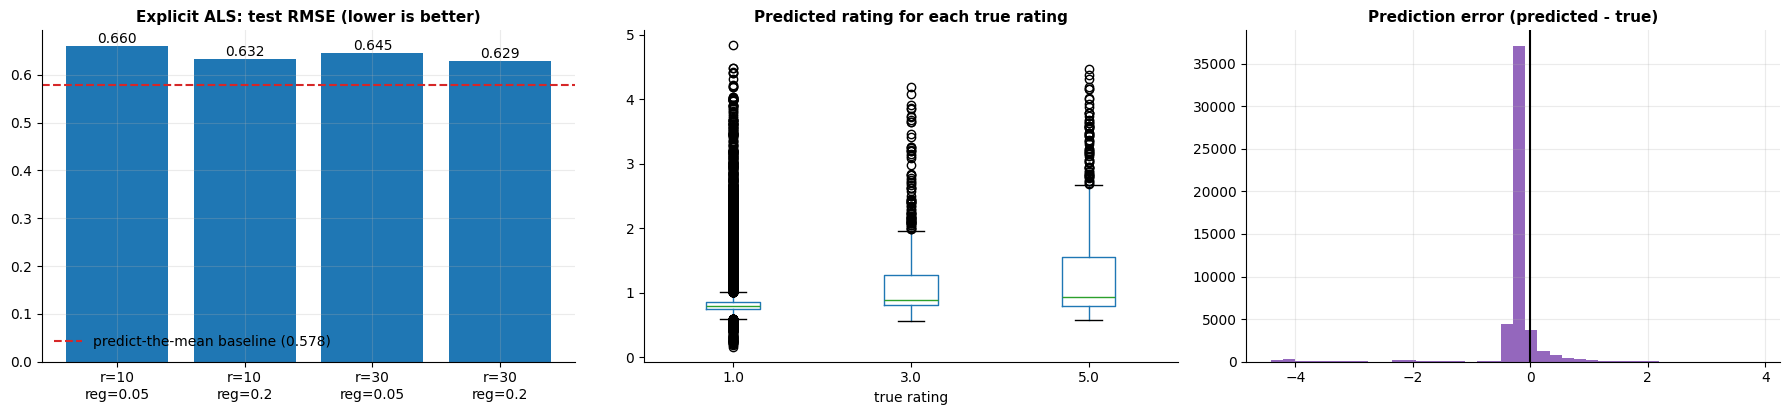

In [18]:
rmse_eval = RegressionEvaluator(metricName="rmse", labelCol="rating", predictionCol="prediction")
te_m = to_matrix(test_ev).join(users_f, "u", "left_semi").join(items_f, "i", "left_semi")
mean_r = tr_full.agg(F.avg("rating")).first()[0]
base_rmse = rmse_eval.evaluate(te_m.withColumn("prediction", F.lit(float(mean_r))))
rows, models = [], {}
for rank, reg in iproduct([10, 30], [0.05, 0.2]):
    m = ALS(userCol="u", itemCol="i", ratingCol="rating", rank=rank, regParam=reg, maxIter=10, nonnegative=True, coldStartStrategy="drop",
            seed=RANDOM_SEED, numUserBlocks=20, numItemBlocks=20).fit(tr_full)
    p = m.transform(te_m); rows.append(dict(rank=rank, regParam=reg, RMSE=rmse_eval.evaluate(p), n_scored=p.count())); models[(rank, reg)] = m
rm = pd.DataFrame(rows).round(4); best_rm = rm.loc[rm["RMSE"].idxmin()]; best_ex = models[(int(best_rm["rank"]), float(best_rm["regParam"]))]
print(rm.to_string(index=False)); print("baseline RMSE (predict the training mean):", round(base_rmse, 4))
R["rmse"], R["rmse_baseline"] = float(best_rm["RMSE"]), round(base_rmse, 4)

res = best_ex.transform(te_m).select("rating", "prediction"); res = res.sample(False, min(1.0, 50000 / max(res.count(), 1)), RANDOM_SEED).toPandas()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
ax[0].bar([f"r={int(r.rank)}\nreg={r.regParam}" for r in rm.itertuples()], rm["RMSE"], color=BLUE); ax[0].bar_label(ax[0].containers[0], fmt="%.3f")
ax[0].axhline(base_rmse, color=RED, ls="--", label=f"predict-the-mean baseline ({base_rmse:.3f})"); ax[0].legend(); ax[0].set_title("Explicit ALS: test RMSE (lower is better)")
res.boxplot(column="prediction", by="rating", ax=ax[1], grid=False); ax[1].set_title("Predicted rating for each true rating"); ax[1].set_xlabel("true rating"); plt.suptitle("")
ax[2].hist(res["prediction"] - res["rating"], bins=40, color=PURPLE); ax[2].axvline(0, color="black"); ax[2].set_title("Prediction error (predicted - true)")
save("07e_explicit_als_rmse")

### 7.7 Cold start, and exporting results for the API
* **New user:** no ALS factors, so we fall back to popular items plus live trends.
* **New item:** no ALS factors either, but it has LSH neighbours (Section 6.3). This is a main reason for the hybrid in Section 9.

The figure shows how much of the test period was **never seen in training**. Then the results needed by the API are saved: ALS top-50 lists for the most active users (plus the evaluation users), product details, and the most popular items.

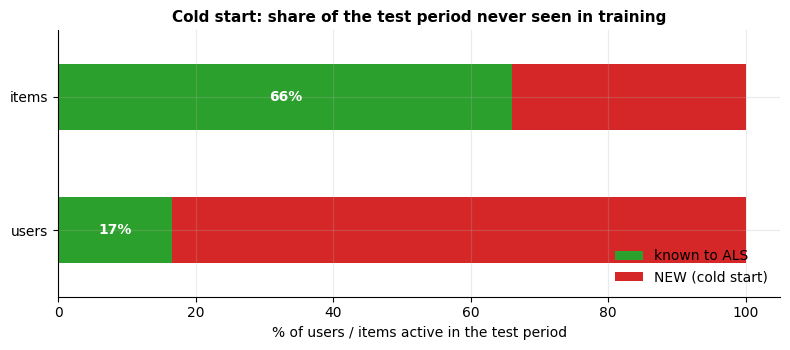

exported to capstone_work/serving -> ['als_recs', 'item_neighbors', 'live_activity.csv', 'live_cat_10m.csv', 'live_trend_10m.csv', 'live_trend_30m.csv', 'live_trend_5m.csv', 'popular', 'products', 'recent_interest']


In [19]:
def share_seen(period_ev, known, col):
    ids = period_ev.select(col).distinct(); return ids.count(), ids.join(known, col, "left_semi").count()
n_tu, s_tu = share_seen(test_ev, users_f, "u"); n_ti, s_ti = share_seen(test_ev, items_f, "i")
R["cold_start"] = {"users_known_pct": round(100 * s_tu / n_tu, 1), "items_known_pct": round(100 * s_ti / n_ti, 1)}
cs = pd.DataFrame({"known to ALS": [100 * s_tu / n_tu, 100 * s_ti / n_ti], "NEW (cold start)": [100 * (1 - s_tu / n_tu), 100 * (1 - s_ti / n_ti)]}, index=["users", "items"])
fig, ax = plt.subplots(figsize=(8, 3.6)); cs.plot.barh(stacked=True, ax=ax, color=[GREEN, RED]); ax.set_xlabel("% of users / items active in the test period")
for k, (_, r) in enumerate(cs.iterrows()): ax.text(r.iloc[0] / 2, k, f"{r.iloc[0]:.0f}%", ha="center", va="center", color="white", weight="bold")
ax.set_title("Cold start: share of the test period never seen in training"); ax.legend(loc="lower right")
save("07f_cold_start")

serve_users = (tr_full.groupBy("u").agg(F.sum("strength").alias("s")).orderBy(F.desc("s")).limit(N_SERVING_USERS).select("u")
               .union(eval_users_t.select("u")).distinct().cache())
(als_recs(als_final, serve_users, 100).join(tr_full.select("u", "i"), ["u", "i"], "left_anti")
    .withColumn("rk", F.row_number().over(Window.partitionBy("u").orderBy(F.desc("score")))).filter("rk <= 50")
    .select(F.col("u").alias("user_id"), F.col("i").alias("product_id"), "score", "rk").write.mode("overwrite").parquet(str(SERVE_DIR / "als_recs")))
prod_doc.select("product_id", "brand", "category_code", "price").write.mode("overwrite").parquet(str(SERVE_DIR / "products"))
(tr_full.groupBy("i").agg(F.sum("strength").alias("score")).orderBy(F.desc("score")).limit(200)
    .select(F.col("i").alias("product_id"), "score").write.mode("overwrite").parquet(str(SERVE_DIR / "popular")))
print("exported to", SERVE_DIR, "->", sorted(p.name for p in SERVE_DIR.iterdir()))

## 8. Real-time stream processing

**Structured Streaming** treats a stream as an ever-growing table and runs the same DataFrame code in small *micro-batches*.

* **Event time:** windows use the time at which the event *happened*, not when Spark received it.
* **Tumbling window:** `window("event_time", "1 minute")` = fixed, non-overlapping 1-minute buckets. Trends over the last 5, 10 or 30 minutes are the sum of the latest 1-minute buckets (computed in pandas below).
* **Sliding window:** `window("event_time", "10 minutes", "2 minutes")` = 10-minute windows that start every 2 minutes. We use it for each user's *recent interest*.
* `approx_count_distinct` (HyperLogLog) counts active users approximately, because exact distinct counts are not supported on streams.
* **Watermark:** in production, `withWatermark("event_time", "2 minutes")` bounds how late data may arrive so Spark can free old state. Here the replay is short and in order, and the results are kept in memory (`complete` mode), so no watermark is needed.

### 8.1 Stream simulator and queries
There is no live shop, so **real events from the dataset are replayed** as a live feed: a background thread writes a small JSON file every `BATCH_INTERVAL_S` seconds and Spark reads each as a new micro-batch. Time is **compressed**: each file stands for `SIM_STEP_S` simulated seconds (60 files = 30 simulated minutes). Timestamps are generated; users, products and event types are real. In production the folder would be replaced by **Kafka, Kinesis or Pub/Sub**.

Three queries run at the same time: **`trend`** (score per product per minute: view = 1, cart = 3, purchase = 5), **`activity`** (events per minute, active users, event mix) and **`interest`** (sliding window per user and category).

> **Performance tip.** Small micro-batches should use few shuffle partitions. The default of 200 makes every micro-batch slow and the stream falls behind, so the cell sets `spark.sql.shuffle.partitions` to 8 for the streaming part only.

In [20]:
STREAM_IN, STREAM_TMP = WORK_DIR / "stream_in", WORK_DIR / "stream_tmp"
for q_ in spark.streams.active: q_.stop()
for d in (STREAM_IN, STREAM_TMP): shutil.rmtree(d, ignore_errors=True); d.mkdir(parents=True)

need = N_BATCHES * ROWS_PER_BATCH
src_pdf = (clean.select("event_type", "product_id", "category_code", "brand", "price", "user_id", "user_session")
           .sample(False, min(1.0, 1.3 * need / n_clean), RANDOM_SEED).limit(need).toPandas()
           .sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True))
n_batches = min(N_BATCHES, len(src_pdf) // ROWS_PER_BATCH); print("replay events:", len(src_pdf), "| micro-batch files:", n_batches)

stream_schema = T.StructType([T.StructField(n, t) for n, t in [
    ("event_time", T.StringType()), ("event_type", T.StringType()), ("product_id", T.LongType()), ("category_code", T.StringType()),
    ("brand", T.StringType()), ("price", T.DoubleType()), ("user_id", T.LongType()), ("user_session", T.StringType())]])

spark.conf.set("spark.sql.shuffle.partitions", "8")                 # small micro-batches need few shuffle partitions
live = (spark.readStream.option("maxFilesPerTrigger", 1).schema(stream_schema).json(str(STREAM_IN))     # one file = one micro-batch
        .withColumn("event_time", F.to_timestamp("event_time")).withColumn("category_code", F.coalesce("category_code", F.lit("unknown")))
        .withColumn("w", W))

def start(name, df):      # results are kept in an in-memory table with the same name as the query
    return df.writeStream.queryName(name).format("memory").outputMode("complete").start()

q_trend = start("trend", live.groupBy(F.window("event_time", "1 minute"), "product_id", "category_code", "brand")
                .agg(F.sum("w").alias("score"), F.count("*").alias("events")))
q_act = start("activity", live.groupBy(F.window("event_time", "1 minute"))
              .agg(F.count("*").alias("events"), F.approx_count_distinct("user_id").alias("active_users"),
                   F.sum((F.col("event_type") == "view").cast("int")).alias("views"), F.sum((F.col("event_type") == "cart").cast("int")).alias("carts"),
                   F.sum((F.col("event_type") == "purchase").cast("int")).alias("purchases")))
q_int = start("interest", live.groupBy(F.window("event_time", "10 minutes", "2 minutes"), "user_id", "category_code").agg(F.sum("w").alias("score")))
queries = [q_trend, q_act, q_int]
print("active streaming queries:", [q_.name for q_ in spark.streams.active])

replay events: 90000 | micro-batch files: 60
active streaming queries: ['activity', 'interest', 'trend']


### 8.2 Run with a live dashboard
The dashboard refreshes while the stream runs. It shows **traffic** (events and active users per minute), the **event mix**, **trending categories** (last 10 minutes), **trending products** (last 5 and 30 minutes) and the **recent interest** of users (latest sliding window). Take a screenshot of the final state for the report.

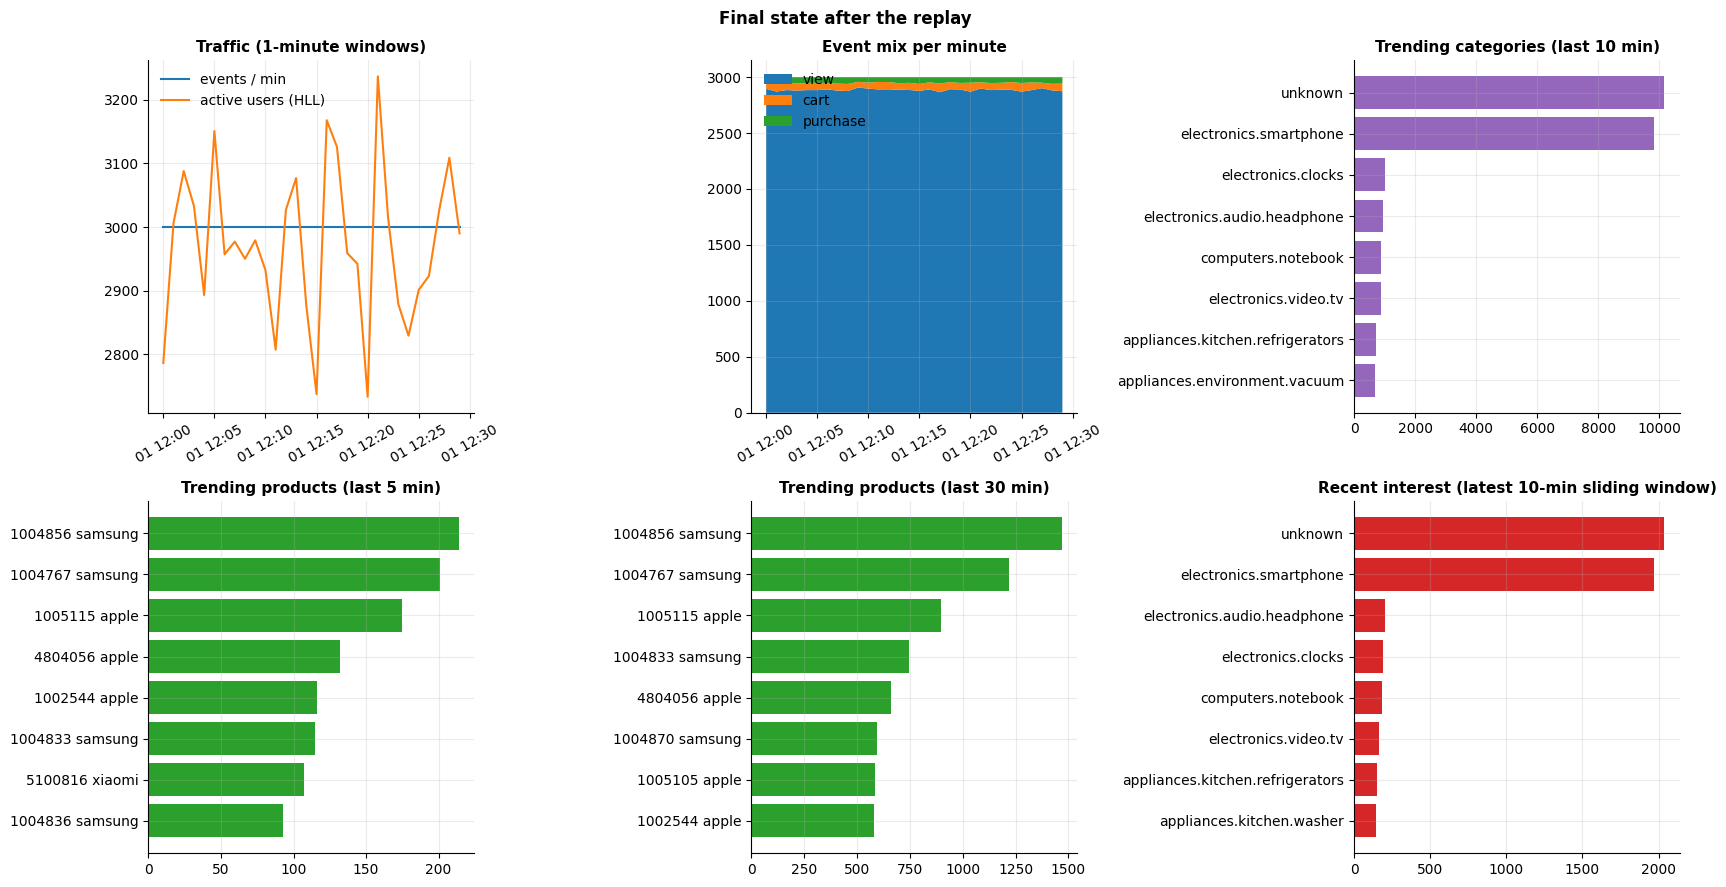

In [21]:
def render(title="Real-time e-commerce dashboard", save_as=None):
    try:
        act = (spark.table("activity").select(F.col("window.start").alias("minute"), "events", "active_users", "views", "carts", "purchases").orderBy("minute").toPandas())
        tr = spark.table("trend").select(F.col("window.start").alias("minute"), "product_id", "brand", "category_code", "score").toPandas()
        it = spark.table("interest").select(F.col("window.start").alias("start"), "user_id", "category_code", "score").toPandas()
    except Exception:
        return                                                   # first batch not processed yet
    if act.empty: return
    tmax = tr["minute"].max(); last = lambda m: tr[tr["minute"] > tmax - pd.Timedelta(minutes=m)]    # latest m one-minute windows
    fig, ax = plt.subplots(2, 3, figsize=(17, 9)); fig.suptitle(title, fontweight="bold")
    ax[0, 0].plot(act["minute"], act["events"], label="events / min", color=BLUE); ax[0, 0].plot(act["minute"], act["active_users"], label="active users (HLL)", color=ORANGE)
    ax[0, 0].legend(); ax[0, 0].set_title("Traffic (1-minute windows)"); ax[0, 0].tick_params(axis="x", rotation=30)
    ax[0, 1].stackplot(act["minute"], act["views"], act["carts"], act["purchases"], labels=["view", "cart", "purchase"], colors=[BLUE, ORANGE, GREEN])
    ax[0, 1].legend(loc="upper left"); ax[0, 1].set_title("Event mix per minute"); ax[0, 1].tick_params(axis="x", rotation=30)
    c = last(10).groupby("category_code")["score"].sum().nlargest(8)[::-1]; ax[0, 2].barh(c.index, c.values, color=PURPLE); ax[0, 2].set_title("Trending categories (last 10 min)")
    for a_, m in [(ax[1, 0], 5), (ax[1, 1], 30)]:
        t = last(m).groupby(["product_id", "brand"])["score"].sum().nlargest(8).reset_index()
        a_.barh((t["product_id"].astype(str) + " " + t["brand"])[::-1], t["score"][::-1], color=GREEN); a_.set_title(f"Trending products (last {m} min)")
    li = it[it["start"] == it["start"].max()].groupby("category_code")["score"].sum().nlargest(8)[::-1]
    ax[1, 2].barh(li.index, li.values, color=RED); ax[1, 2].set_title("Recent interest (latest 10-min sliding window)")
    plt.tight_layout()
    if save_as: plt.savefig(FIG_DIR / f"{save_as}.png", dpi=150, bbox_inches="tight")
    plt.show()

sim_start = pd.Timestamp("2024-01-01 12:00:00")
def replay():                                                    # background thread: one JSON file per micro-batch
    for b in range(n_batches):
        chunk = src_pdf.iloc[b * ROWS_PER_BATCH:(b + 1) * ROWS_PER_BATCH].copy()
        offs = np.sort(np.random.uniform(0, SIM_STEP_S, len(chunk)))
        chunk.insert(0, "event_time", (sim_start + pd.to_timedelta(b * SIM_STEP_S + offs, unit="s")).strftime("%Y-%m-%d %H:%M:%S"))
        tmp = STREAM_TMP / f"b{b:04d}.json"; chunk.to_json(tmp, orient="records", lines=True)
        os.replace(tmp, STREAM_IN / f"b{b:04d}.json")           # atomic move: Spark never reads a half-written file
        time.sleep(BATCH_INTERVAL_S)

th = threading.Thread(target=replay, daemon=True); th.start()
while th.is_alive():
    time.sleep(6); clear_output(wait=True); render()
t_end = time.time()
for q_ in queries: q_.processAllAvailable()                      # drain: make sure every file has been processed
drain_s = time.time() - t_end
clear_output(wait=True); render("Final state after the replay", save_as="08a_dashboard_final")

### 8.3 Streaming performance and correctness
* **Does the stream keep up?** Each micro-batch must be processed faster than the replay writes a new file (`BATCH_INTERVAL_S`). The left figure shows the processing time of every micro-batch against that limit; `drain` is how long Spark needed to finish after the last file arrived (small = no backlog).
* **Throughput:** rows per second from Spark's own progress reports.
* **Correctness:** the streaming result is compared with the same aggregation computed in **batch mode** on the same files. Event counts must be identical; the active-user count is approximate (HyperLogLog), so we report its relative error.

{'trigger_ms': 501, 'rows_per_s': 3140, 'drain_s': 0.0, 'keeps_up': True, 'events_exact': True, 'hll_max_rel_error': 0.0863, 'events_total': 90000}


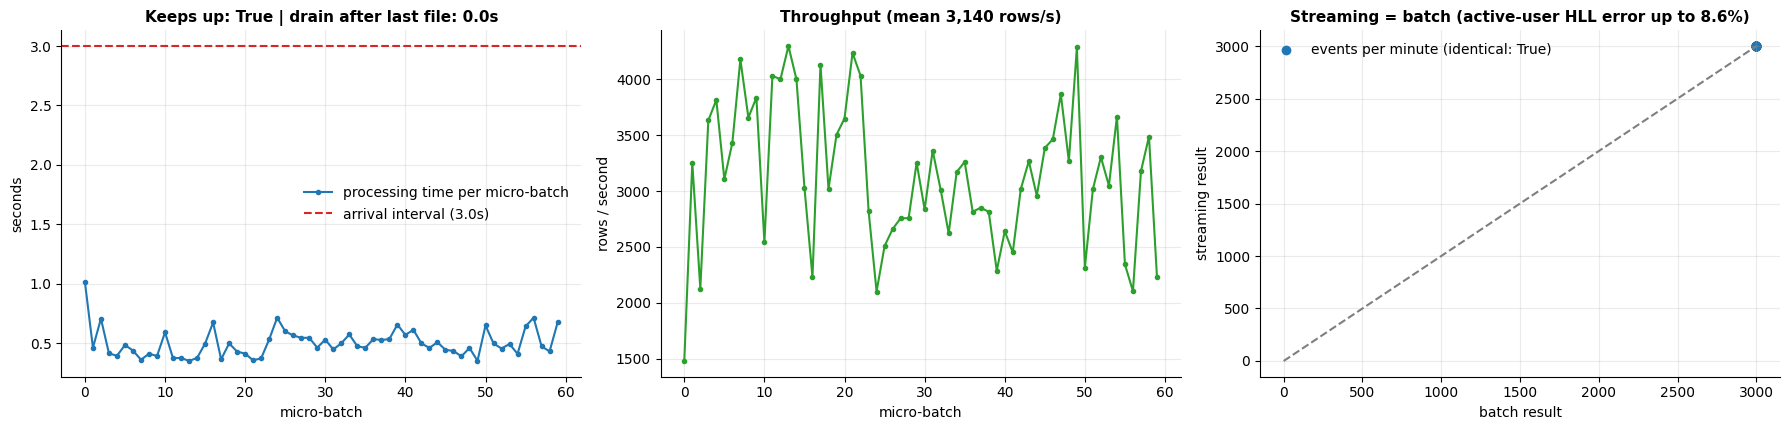

In [22]:
prog = [p for p in q_act.recentProgress if p["numInputRows"] > 0]
trig_ms = np.array([p["durationMs"]["triggerExecution"] for p in prog]); rows_s = np.array([p.get("processedRowsPerSecond", np.nan) for p in prog])

act = (spark.table("activity").select(F.col("window.start").alias("minute"), "events", "active_users").toPandas())
batch = (spark.read.schema(stream_schema).json(str(STREAM_IN)).withColumn("event_time", F.to_timestamp("event_time"))
         .groupBy(F.window("event_time", "1 minute").getField("start").alias("minute"))
         .agg(F.count("*").alias("events_b"), F.countDistinct("user_id").alias("users_b")).toPandas())
cmp_ = act.merge(batch, on="minute", how="outer").sort_values("minute")
events_exact = bool((cmp_["events"] == cmp_["events_b"]).all()); hll_err = float(((cmp_["active_users"] - cmp_["users_b"]).abs() / cmp_["users_b"].replace(0, np.nan)).max())
keeps_up = bool(trig_ms.mean() / 1000 < BATCH_INTERVAL_S)
R["streaming"] = {"trigger_ms": round(float(trig_ms.mean())), "rows_per_s": round(float(np.nanmean(rows_s))), "drain_s": round(drain_s, 1),
                  "keeps_up": keeps_up, "events_exact": events_exact, "hll_max_rel_error": round(hll_err, 4), "events_total": int(len(src_pdf))}
print(R["streaming"])

fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
ax[0].plot(trig_ms / 1000, marker="o", ms=3, color=BLUE, label="processing time per micro-batch"); ax[0].axhline(BATCH_INTERVAL_S, color=RED, ls="--", label=f"arrival interval ({BATCH_INTERVAL_S}s)")
ax[0].set_xlabel("micro-batch"); ax[0].set_ylabel("seconds"); ax[0].legend(); ax[0].set_title(f"Keeps up: {keeps_up} | drain after last file: {drain_s:.1f}s")
ax[1].plot(rows_s, marker="o", ms=3, color=GREEN); ax[1].set_xlabel("micro-batch"); ax[1].set_ylabel("rows / second"); ax[1].set_title(f"Throughput (mean {np.nanmean(rows_s):,.0f} rows/s)")
ax[2].scatter(cmp_["events_b"], cmp_["events"], color=BLUE, label=f"events per minute (identical: {events_exact})")
ax[2].plot([0, cmp_["events_b"].max()], [0, cmp_["events_b"].max()], "--", color=GREY); ax[2].set_xlabel("batch result"); ax[2].set_ylabel("streaming result")
ax[2].legend(); ax[2].set_title(f"Streaming = batch (active-user HLL error up to {hll_err:.1%})")
save("08b_stream_performance")

### 8.4 Hand-over to the recommender
The stream feeds the recommender in two ways: the **trending score** re-ranks the recommendations, and a user's **recent categories** boost matching items. So a new search or purchase changes what the user sees within minutes, which is the problem stated in the abstract. The cell saves the latest trends (5/10/30 minutes) and the recent interests as files for the API, then stops the queries. In production the hand-over would use Kafka, Redis or Delta tables instead of files.

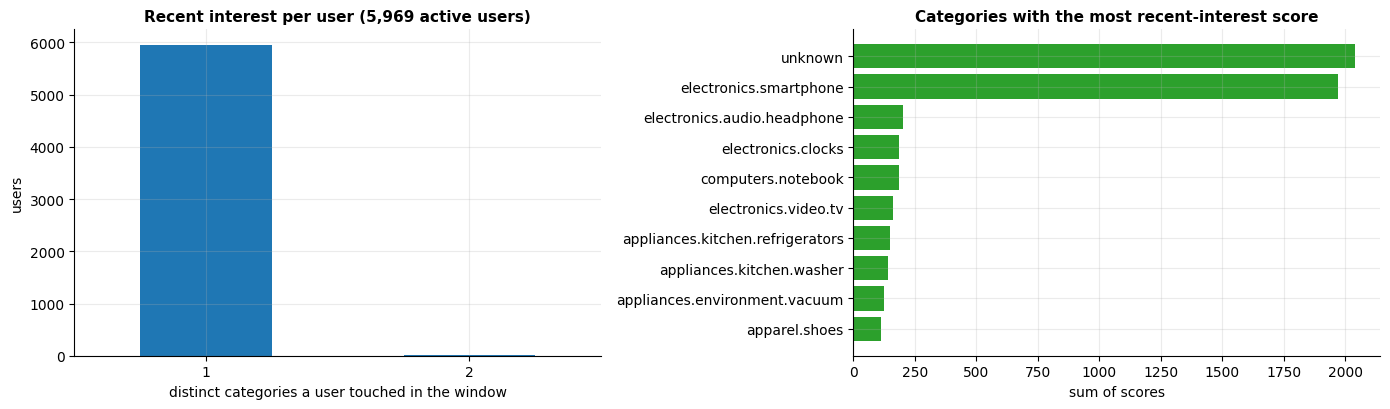

live snapshots written to capstone_work/serving


In [23]:
tr = spark.table("trend").select(F.col("window.start").alias("minute"), "product_id", "brand", "category_code", "score").toPandas()
it = spark.table("interest").select(F.col("window.start").alias("start"), "user_id", "category_code", "score").toPandas()
tmax = tr["minute"].max()
for m in (5, 10, 30):
    (tr[tr["minute"] > tmax - pd.Timedelta(minutes=m)].groupby(["product_id", "brand", "category_code"])["score"].sum().nlargest(50)
       .reset_index().to_csv(SERVE_DIR / f"live_trend_{m}m.csv", index=False))
interest = it[it["start"] == it["start"].max()][["user_id", "category_code", "score"]]; interest.to_parquet(SERVE_DIR / "recent_interest.parquet", index=False)

per_user = interest.groupby("user_id")["category_code"].nunique(); top_ci = interest.groupby("category_code")["score"].sum().nlargest(10)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
per_user.value_counts().sort_index().plot.bar(ax=ax[0], rot=0, color=BLUE); ax[0].set_xlabel("distinct categories a user touched in the window"); ax[0].set_ylabel("users")
ax[0].set_title(f"Recent interest per user ({len(per_user):,} active users)")
ax[1].barh(top_ci.index, top_ci.values, color=GREEN); ax[1].set_title("Categories with the most recent-interest score"); ax[1].set_xlabel("sum of scores")
save("08c_recent_interest")

for q_ in queries: q_.stop()
spark.conf.set("spark.sql.shuffle.partitions", str(SHUFFLE_PARTS))      # back to the batch setting
print("live snapshots written to", SERVE_DIR)

## 9. Hybrid recommender

$$\text{score}(u,i)=\alpha\,\widehat{ALS}(u,i)+\beta\sum_{j\in R_u}sim(i,j)+\gamma\,\widehat{trend}(i)$$

* $\widehat{ALS}$: the ALS score divided by the user's best ALS score (0 to 1),
* $R_u$: the user's **3 most recent items**; $sim(i,j)$ comes from the **LSH neighbour table** (content-based part),
* $\widehat{trend}$: trending score scaled to 0 to 1. For the **offline test** it is computed from the last 7 days before the test period; in the **API** the live stream plays this role.

### 9.1 Item-neighbour table (content-based part)
Products are compared **only within the most viewed `SIM_POOL` products** and the 20 best neighbours per product are kept (ties are broken by popularity), so the similarity join stays small. This is the slowest cell of the notebook because many products share an identical text.

neighbour rows: 421,835 | items with neighbours: 28,688


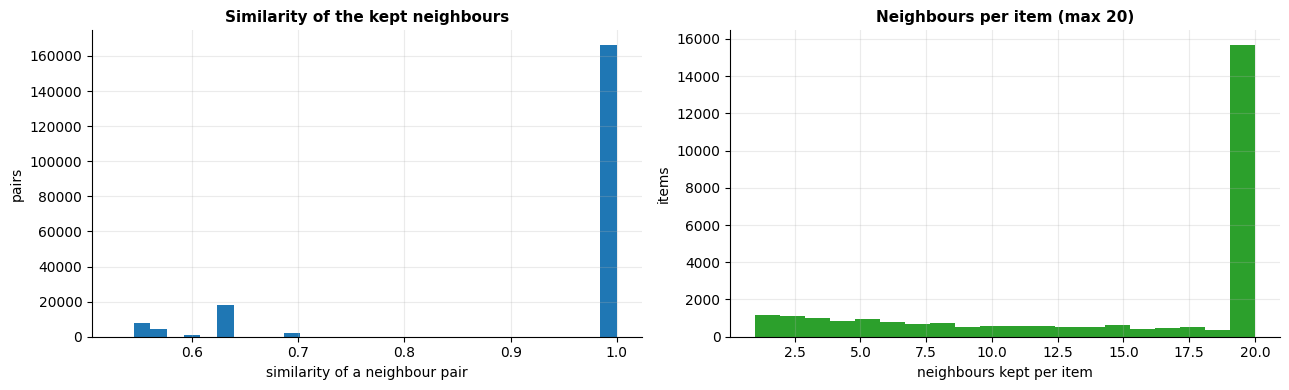

In [24]:
pool = prod_hash.orderBy(F.desc("views")).limit(SIM_POOL).cache()
nb = (lsh.approxSimilarityJoin(pool, pool, 0.5, distCol="jd").filter(F.col("datasetA.product_id") != F.col("datasetB.product_id"))
      .select(F.col("datasetA.product_id").alias("product_id"), F.col("datasetB.product_id").alias("neighbor_id"),
              (1 - F.col("jd")).alias("sim"), F.col("datasetB.views").alias("nviews")))
nb = (nb.withColumn("rk", F.row_number().over(Window.partitionBy("product_id").orderBy(F.desc("sim"), F.desc("nviews"))))
        .filter(F.col("rk") <= 20).select("product_id", "neighbor_id", "sim").cache())
nb.write.mode("overwrite").parquet(str(SERVE_DIR / "item_neighbors"))
n_nb, n_nb_items = nb.count(), nb.select("product_id").distinct().count(); R["neighbour_table"] = {"rows": n_nb, "items": n_nb_items}
print(f"neighbour rows: {n_nb:,} | items with neighbours: {n_nb_items:,}")

sims = nb.select("sim").sample(False, min(1.0, 200000 / max(n_nb, 1)), RANDOM_SEED).toPandas()["sim"]; per_item = nb.groupBy("product_id").count().toPandas()["count"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(sims, bins=30, color=BLUE); ax[0].set_xlabel("similarity of a neighbour pair"); ax[0].set_ylabel("pairs"); ax[0].set_title("Similarity of the kept neighbours")
ax[1].hist(per_item, bins=20, color=GREEN); ax[1].set_xlabel("neighbours kept per item"); ax[1].set_ylabel("items"); ax[1].set_title("Neighbours per item (max 20)")
save("09a_neighbour_table")

### 9.2 Hybrid vs ALS-only on the test period
For `N_HYB` test users we collect the ALS candidates, each user's 3 most recent items, the neighbour table and the 7-day trend into pandas dictionaries, so that many weight settings can be tried quickly. **Candidates** are the user's ALS top-100 plus the LSH neighbours of the 3 recent items; items the user already knew are removed.

The figure shows (left) the metrics of each setting together with the popularity baseline for the same users, (middle) the **relative change in Precision@10 compared with ALS-only**, and (right) a sweep over `β` and `γ`.

> **Reading the result honestly.** If the hybrid beats ALS-only, content and trend add information. If it does not beat *popularity*, say so too. The offline trend is only a proxy for the live stream, and the product text is short. The benefits that offline metrics hide are **cold start** (next cell) and **freshness** (live trends).

users: 1697 | with ALS recs: 1697 | with recent items: 1697


                model  alpha  beta  gamma   P@10   R@10  HitRate@10
             ALS only      1   0.0    0.0 0.0082 0.0715      0.0807
  ALS + content (LSH)      1   0.3    0.0 0.0100 0.0897      0.0978
          ALS + trend      1   0.0    0.3 0.0090 0.0792      0.0884
ALS + content + trend      1   0.3    0.3 0.0101 0.0902      0.0996
        content heavy      1   1.0    0.3 0.0105 0.0951      0.1037
          trend heavy      1   0.3    1.0 0.0114 0.1005      0.1114
popularity baseline, same users: {'precision': 0.013, 'recall': 0.1154, 'hit_rate': 0.1249}


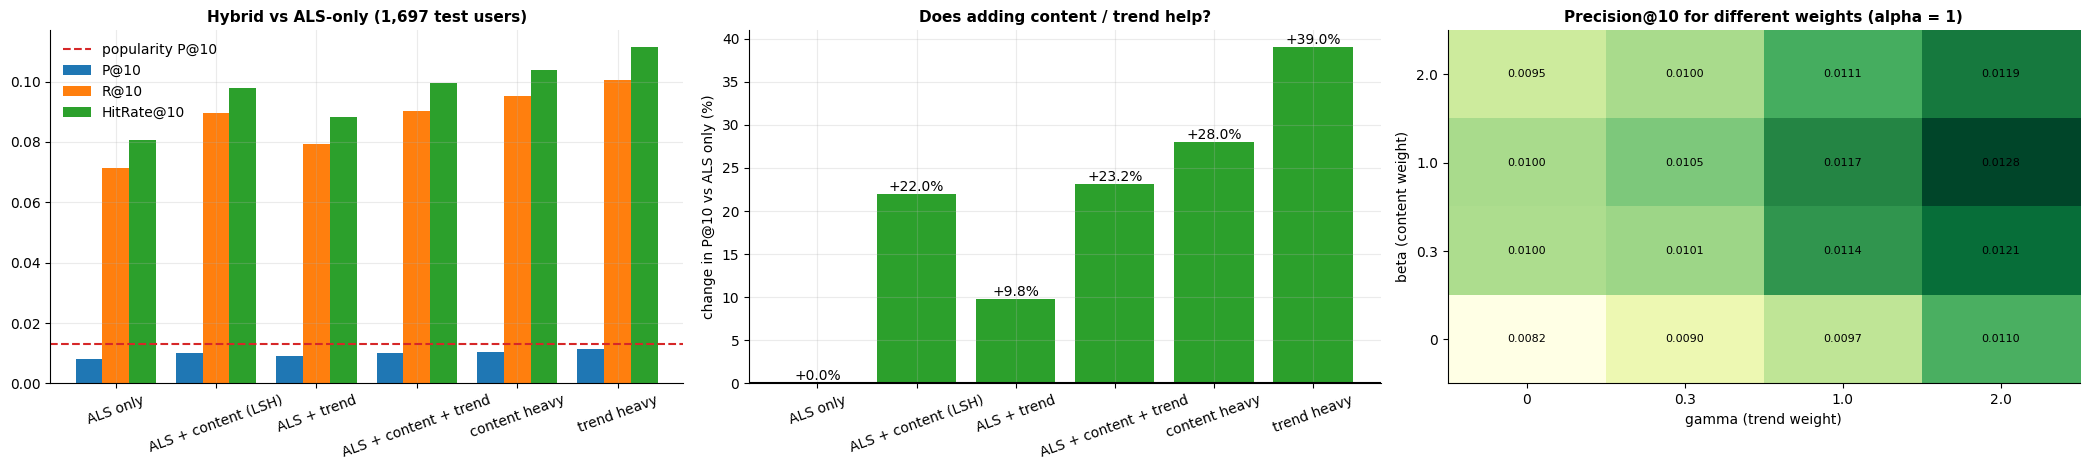

In [25]:
hyb_users = eval_users_t.orderBy(F.rand(RANDOM_SEED)).limit(N_HYB).cache()
seen_all = tr_full.join(F.broadcast(hyb_users), "u", "left_semi").select("u", "i")
als_df = als_recs(als_final, hyb_users, 100).join(tr_full.select("u", "i"), ["u", "i"], "left_anti").toPandas()
als_pd = {u: dict(zip(g["i"], g["score"])) for u, g in als_df.groupby("u")}
recent = (inter.filter(F.col("t") < t_test).join(F.broadcast(hyb_users), "u", "left_semi").groupBy("u", "i").agg(F.max("t").alias("last_t"))
          .withColumn("rk", F.row_number().over(Window.partitionBy("u").orderBy(F.desc("last_t")))).filter("rk <= 3").toPandas())
recent_pd = recent.groupby("u")["i"].agg(list).to_dict()
neigh = {p: list(zip(g["neighbor_id"], g["sim"])) for p, g in nb.toPandas().groupby("product_id")}
tdf = inter.filter((F.col("t") >= t_test - 7 * 86400) & (F.col("t") < t_test)).groupBy("i").agg(F.sum("w").alias("s")).toPandas()
trend = dict(zip(tdf["i"], tdf["s"] / tdf["s"].max()))
seen_pd = seen_all.toPandas().groupby("u")["i"].agg(set).to_dict()
truth_h = truth_t.join(F.broadcast(hyb_users), "u", "left_semi").cache()
truth_pd = truth_h.toPandas().groupby("u")["i"].agg(set).to_dict()
print("users:", len(truth_pd), "| with ALS recs:", len(als_pd), "| with recent items:", len(recent_pd))

def hybrid_topk(u, a, b, g, K=10):
    base = als_pd.get(u, {}); top = max(base.values()) if base else 1.0
    score = {i: a * s / top for i, s in base.items()}                       # ALS part
    for j in recent_pd.get(u, []):                                          # content part: neighbours of recent items
        for i, sim in neigh.get(j, []): score[i] = score.get(i, 0.0) + b * sim
    for i in score: score[i] += g * trend.get(i, 0.0)                       # trend part
    seen = seen_pd.get(u, set())
    return sorted((i for i in score if i not in seen), key=score.get, reverse=True)[:K]

def eval_weights(a, b, g, K=10):
    P, Rc, H = [], [], []
    for u, rel in truth_pd.items():
        hit = len(set(hybrid_topk(u, a, b, g, K)) & rel); P.append(hit / K); Rc.append(hit / len(rel)); H.append(float(hit > 0))
    return np.mean(P), np.mean(Rc), np.mean(H)

configs = [("ALS only", 1, 0, 0), ("ALS + content (LSH)", 1, 0.3, 0), ("ALS + trend", 1, 0, 0.3), ("ALS + content + trend", 1, 0.3, 0.3),
           ("content heavy", 1, 1.0, 0.3), ("trend heavy", 1, 0.3, 1.0)]
hy = pd.DataFrame([dict(model=n, alpha=a, beta=b, gamma=g, **dict(zip(["P@10", "R@10", "HitRate@10"], eval_weights(a, b, g)))) for n, a, b, g in configs]).round(4)
pop_h = metrics_at_k(popularity_recs(tr_full, hyb_users), tr_full, truth_h)[10]
print(hy.to_string(index=False)); print("popularity baseline, same users:", {k: round(v, 4) for k, v in pop_h.items()})
R["hybrid"] = hy.to_dict("records"); R["pop_same_users"] = pop_h

betas, gammas = [0, 0.3, 1.0, 2.0], [0, 0.3, 1.0, 2.0]
grid = np.array([[eval_weights(1, b, g)[0] for g in gammas] for b in betas])
fig, ax = plt.subplots(1, 3, figsize=(21, 4.8))
hy.set_index("model")[["P@10", "R@10", "HitRate@10"]].plot.bar(ax=ax[0], rot=20, width=0.8, color=[BLUE, ORANGE, GREEN]); ax[0].set_xlabel("")
ax[0].axhline(pop_h["precision"], color=RED, ls="--", label="popularity P@10"); ax[0].legend(); ax[0].set_title(f"Hybrid vs ALS-only ({len(truth_pd):,} test users)")
base_p = hy.loc[hy["model"] == "ALS only", "P@10"].iloc[0]; rel = 100 * (hy["P@10"] / max(base_p, 1e-12) - 1)
ax[1].bar(hy["model"], rel, color=[GREEN if r >= 0 else RED for r in rel]); ax[1].axhline(0, color="black"); ax[1].tick_params(axis="x", rotation=20)
ax[1].bar_label(ax[1].containers[0], fmt="%+.1f%%"); ax[1].set_ylabel("change in P@10 vs ALS only (%)"); ax[1].set_title("Does adding content / trend help?")
im = ax[2].imshow(grid, cmap="YlGn", origin="lower", aspect="auto"); ax[2].set_xticks(range(len(gammas))); ax[2].set_xticklabels(gammas)
ax[2].set_yticks(range(len(betas))); ax[2].set_yticklabels(betas); ax[2].set_xlabel("gamma (trend weight)"); ax[2].set_ylabel("beta (content weight)"); ax[2].grid(False)
for (i_, j_), v_ in np.ndenumerate(grid): ax[2].text(j_, i_, f"{v_:.4f}", ha="center", va="center", fontsize=8)
ax[2].set_title("Precision@10 for different weights (alpha = 1)")
save("09b_hybrid")

### 9.3 Cold start: who can recommend new items?
Items that become relevant in the test period but were **never seen in training** have no ALS factors, so ALS cannot score them at all. The LSH component only needs the product text, so it can. This is the benefit of the hybrid that Precision@10 on known items does not show.

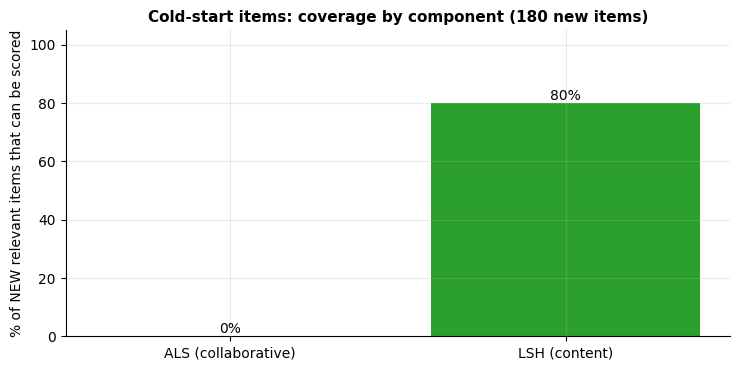

In [26]:
test_items = test_ev.filter("w >= 3").select("i").distinct()
new_items = test_items.join(items_f, "i", "left_anti")                                                  # relevant in the test period, unknown to ALS
n_new = new_items.count(); has_doc = new_items.join(prod_hash.select(F.col("product_id").alias("i")), "i", "left_semi").count()    # LSH can describe them
R["cold_start_items"] = {"new_relevant_items": n_new, "lsh_can_match": has_doc}
cov = pd.Series({"ALS (collaborative)": 0.0, "LSH (content)": 100 * has_doc / max(n_new, 1)})
fig, ax = plt.subplots(figsize=(7.5, 3.8)); ax.bar(cov.index, cov.values, color=[RED, GREEN]); ax.set_ylim(0, 105); ax.bar_label(ax.containers[0], fmt="%.0f%%")
ax.set_ylabel("% of NEW relevant items that can be scored"); ax.set_title(f"Cold-start items: coverage by component ({n_new:,} new items)")
save("09c_cold_start_coverage")

## 10. Serving, containers and cloud

### 10.1 REST API
The API (FastAPI) serves the saved batch results (ALS lists, LSH neighbours, popular items) and merges the **live trends and recent interests** from the stream at request time. Live files are re-read whenever they change, so new stream results appear without restarting.

| Endpoint | Purpose |
|---|---|
| `GET /health` | health check |
| `GET /recommend/{user_id}?k=10` | personalised Top-K (**new users** get popular + trending items) |
| `GET /similar/{product_id}?k=10` | similar products from LSH |
| `GET /trending?window=5m\|10m\|30m` | live trending products |

Score for a known user: `1.0·ALS + 0.3·trend + 0.2·(item is in a recently viewed category)`.

In [27]:
os.makedirs("ecom_reco_project/app", exist_ok=True)

In [28]:
%%writefile ecom_reco_project/app/main.py
import os
from pathlib import Path

import pandas as pd
from fastapi import FastAPI, HTTPException, Query

DATA = Path(os.environ.get("DATA_DIR", "capstone_work/serving"))
ALPHA, GAMMA, DELTA = 1.0, 0.3, 0.2          # weights: ALS, trending, recent-category boost
app = FastAPI(title="E-commerce Recommendation API", version="1.0.0")
STATE = {"live_mtime": None}


def load_static():
    # batch results: loaded once at start-up
    recs = pd.read_parquet(DATA / "als_recs").sort_values("rk")
    STATE["als"] = {int(u): list(zip(g["product_id"].astype(int), g["score"].astype(float))) for u, g in recs.groupby("user_id")}
    prods = pd.read_parquet(DATA / "products")
    STATE["products"] = {int(r.product_id): {"brand": r.brand, "category": r.category_code, "price": float(r.price)} for r in prods.itertuples()}
    pop = pd.read_parquet(DATA / "popular").sort_values("score", ascending=False)
    STATE["popular"] = [(int(r.product_id), float(r.score)) for r in pop.itertuples()]
    nb = pd.read_parquet(DATA / "item_neighbors").sort_values("sim", ascending=False)
    STATE["neighbors"] = {int(p): list(zip(g["neighbor_id"].astype(int), g["sim"].astype(float))) for p, g in nb.groupby("product_id")}


def load_live():
    # speed-layer results: re-read only when the streaming job has written new files
    files = [DATA / f"live_trend_{w}.csv" for w in ("5m", "10m", "30m")] + [DATA / "recent_interest.parquet"]
    mtimes = [f.stat().st_mtime if f.exists() else 0 for f in files]
    if mtimes == STATE["live_mtime"]:
        return
    STATE["live_mtime"], STATE["trend"], STATE["trend_norm"] = mtimes, {}, {}
    for w, f in zip(("5m", "10m", "30m"), files):
        df = pd.read_csv(f) if f.exists() else pd.DataFrame(columns=["product_id", "score"])
        STATE["trend"][w] = [(int(r.product_id), float(r.score)) for r in df.itertuples()]
        top = max((s for _, s in STATE["trend"][w]), default=1.0) or 1.0
        STATE["trend_norm"][w] = {p: s / top for p, s in STATE["trend"][w]}
    ri = DATA / "recent_interest.parquet"
    STATE["interest"] = pd.read_parquet(ri).groupby("user_id")["category_code"].agg(set).to_dict() if ri.exists() else {}


def item(pid, score):
    info = STATE["products"].get(pid, {})
    return {"product_id": pid, "brand": info.get("brand"), "category": info.get("category"), "price": info.get("price"), "score": round(float(score), 4)}


load_static()
load_live()


@app.get("/health")
def health():
    return {"status": "ok", "users": len(STATE["als"]), "products": len(STATE["products"])}


@app.get("/recommend/{user_id}")
def recommend(user_id: int, k: int = Query(10, ge=1, le=50)):
    load_live()
    trend = STATE["trend_norm"]["10m"]
    if user_id in STATE["als"]:                                   # known user: ALS + trend + recent-category boost
        recs = STATE["als"][user_id]
        top = max(s for _, s in recs) or 1.0
        interest = STATE["interest"].get(user_id, set())
        scored = {pid: ALPHA * s / top + GAMMA * trend.get(pid, 0.0) + (DELTA if STATE["products"].get(pid, {}).get("category") in interest else 0.0)
                  for pid, s in recs}
        source = "als+trend+recent_interest"
    else:                                                         # new user (cold start): popular + trending items
        top = STATE["popular"][0][1] if STATE["popular"] else 1.0
        scored = {pid: ALPHA * s / top + GAMMA * trend.get(pid, 0.0) for pid, s in STATE["popular"]}
        for pid, s in trend.items():
            scored.setdefault(pid, GAMMA * s)
        source = "popular+trend"
    best = sorted(scored.items(), key=lambda x: x[1], reverse=True)[:k]
    return {"user_id": user_id, "source": source, "items": [item(p, s) for p, s in best]}


@app.get("/similar/{product_id}")
def similar(product_id: int, k: int = Query(10, ge=1, le=50)):
    nbrs = STATE["neighbors"].get(product_id)
    if not nbrs:
        raise HTTPException(status_code=404, detail=f"no neighbours for product {product_id}")
    return {"product_id": product_id, "items": [item(p, s) for p, s in nbrs[:k]]}


@app.get("/trending")
def trending(window: str = Query("5m", pattern="^(5m|10m|30m)$"), k: int = Query(10, ge=1, le=50)):
    load_live()
    return {"window": window, "items": [item(p, s) for p, s in STATE["trend"][window][:k]]}

Overwriting ecom_reco_project/app/main.py


In [29]:
%%writefile ecom_reco_project/app/requirements.txt
fastapi>=0.110
uvicorn[standard]>=0.29
pandas>=2.0
pyarrow>=14.0

Overwriting ecom_reco_project/app/requirements.txt


The next cell tests the API **inside the notebook** (no server needed): every endpoint is called once, the **response time** of 300 `/recommend` calls is measured, and the figure shows the latency distribution and which recommendation path was used. To run it as a real server:

```bash
cd ecom_reco_project/app && DATA_DIR=../../capstone_work/serving uvicorn main:app --port 8000
# then open http://localhost:8000/docs for the interactive Swagger page
```

{
 "user_id": 510335574,
 "source": "als+trend+recent_interest",
 "items": [
  {
   "product_id": 1004659,
   "brand": "samsung",
   "category": "electronics.smartphone",
   "price": 728.44,
   "score": 1.0613
  },
  {
   "product_id": 1005239,
   "brand": "xiaomi",
   "category": "electronics.smartphone",
   "price": 257.15,
   "score": 0.993
  },
  {
   "product_id": 1005159,
   "brand": "xiaomi",
   "category": "electronics.smartphone",
   "price": 225.13,
   "score": 0.9323
  },
  {
   "product_id": 1307073,
   "brand": "acer",
   "category": "computers.notebook",
   "price": 694.71,
   "s
status codes: {'/health': 200, '/recommend/{known user}': 200, '/recommend/{new user}': 200, '/similar/{product}': 200, '/trending?window=5m': 200}
new user source: popular+trend
{'mean_ms': 2.55, 'p95_ms': 2.91, 'all_ok': True}


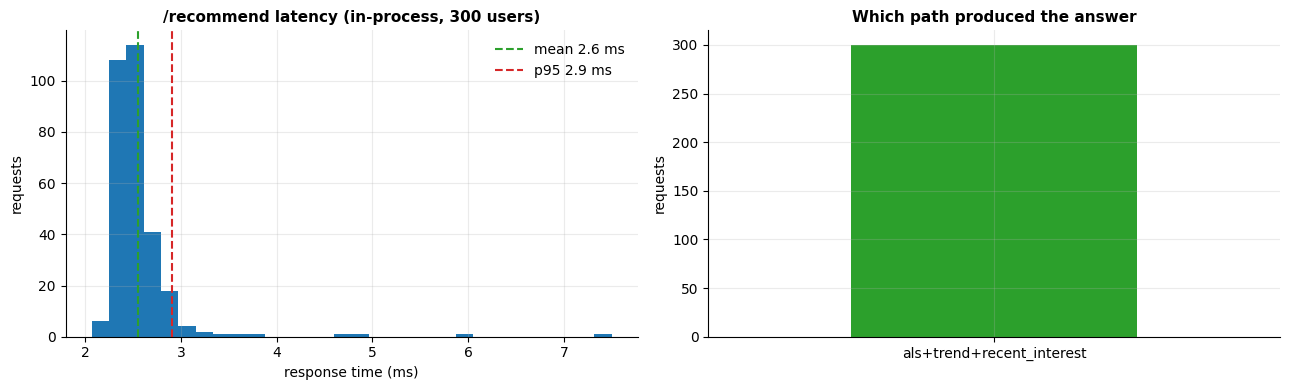

In [30]:
import importlib.util
os.environ["DATA_DIR"] = str(SERVE_DIR.resolve())
spec = importlib.util.spec_from_file_location("reco_api", "ecom_reco_project/app/main.py")
reco_api = importlib.util.module_from_spec(spec); spec.loader.exec_module(reco_api)
from fastapi.testclient import TestClient
client = TestClient(reco_api.app)

u0 = int(next(iter(truth_pd))); r = client.get(f"/recommend/{u0}", params={"k": 5}).json(); print(json.dumps(r, indent=1)[:600])
p0 = r["items"][0]["product_id"]
status = {"/health": client.get("/health").status_code, "/recommend/{known user}": client.get(f"/recommend/{u0}").status_code,
          "/recommend/{new user}": client.get("/recommend/1").status_code, "/similar/{product}": client.get(f"/similar/{p0}").status_code,
          "/trending?window=5m": client.get("/trending", params={"window": "5m"}).status_code}
print("status codes:", status); print("new user source:", client.get("/recommend/1").json()["source"])

sample = random.sample(list(truth_pd), min(300, len(truth_pd))); lats, sources = [], []
for u in sample:
    s0 = time.perf_counter(); resp = client.get(f"/recommend/{int(u)}", params={"k": 10}); lats.append((time.perf_counter() - s0) * 1000); sources.append(resp.json()["source"])
lats = np.array(lats); R["api"] = {"mean_ms": round(float(lats.mean()), 2), "p95_ms": round(float(np.percentile(lats, 95)), 2), "all_ok": all(c == 200 for c in status.values())}
print(R["api"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(lats, bins=30, color=BLUE); ax[0].axvline(lats.mean(), color=GREEN, ls="--", label=f"mean {lats.mean():.1f} ms"); ax[0].axvline(np.percentile(lats, 95), color=RED, ls="--", label=f"p95 {np.percentile(lats, 95):.1f} ms")
ax[0].legend(); ax[0].set_xlabel("response time (ms)"); ax[0].set_ylabel("requests"); ax[0].set_title("/recommend latency (in-process, 300 users)")
pd.Series(sources).value_counts().plot.bar(ax=ax[1], rot=0, color=GREEN); ax[1].set_title("Which path produced the answer"); ax[1].set_ylabel("requests")
save("10a_api_latency")

### 10.2 Docker
The image contains **only the API** (it serves pre-computed results, so Spark is not needed inside it). The same image runs on a laptop, a server or any cloud.

In [31]:
%%writefile ecom_reco_project/Dockerfile
FROM python:3.11-slim
WORKDIR /app
COPY app/requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app/ .
ENV DATA_DIR=/data
EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=3s --retries=3 \
  CMD python -c "import urllib.request,sys; sys.exit(0 if urllib.request.urlopen('http://localhost:8000/health').status==200 else 1)"
RUN useradd -m appuser
USER appuser
CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000"]

Overwriting ecom_reco_project/Dockerfile


```bash
cd ecom_reco_project
docker build -t ecom-reco-api:1.0 .
docker run -p 8000:8000 -v $(pwd)/../capstone_work/serving:/data:ro ecom-reco-api:1.0
curl "http://localhost:8000/recommend/<user_id>?k=5"
```
> The Dockerfile and commands are provided, but **the image was not built inside this notebook**. Build and test it once on a machine with Docker before claiming it is deployed.

### 10.3 Running on a cloud platform
The Spark code runs unchanged on a managed Spark service; only the master and the paths change (`s3a://...`, `gs://...`).

| Part | Cloud option |
|---|---|
| Data storage | Amazon S3, Google Cloud Storage, Azure Blob Storage |
| Spark processing | Databricks, Amazon EMR, Google Cloud Dataproc |
| Live events | Kafka / Amazon Kinesis / Google Pub/Sub instead of the replay folder |
| API container | AWS ECS or Elastic Beanstalk, Google Cloud Run, or Kubernetes |

**Steps:** (1) upload the Parquet data to object storage; (2) create a small cluster (2 to 4 workers) and attach this notebook or submit it as a job; (3) change `WORK_DIR` to the bucket path and rerun; (4) copy the `serving` folder to the bucket used by the API container; (5) deploy the Docker image and open `/docs`.

```bash
spark-submit --master yarn --deploy-mode cluster --executor-memory 16g --executor-cores 4 job.py            # EMR / YARN
gcloud dataproc jobs submit pyspark gs://BUCKET/job.py --cluster=ecom --region=REGION                      # Dataproc
```
**Benefits:** easy scaling, pay only for use, no hardware to manage. **Limits:** cost for long-running clusters, data-transfer time, and less control over the environment.

## 11. Evaluation and results

### 11.1 Scalability
Run time is measured for an aggregation and for ALS training (5 iterations) on 25%, 50% and 100% of the interactions. A curve that grows **slower than the dashed linear line** means Spark is spreading the work well. To study scaling *across machines*, repeat the 100% run on a cloud cluster with 1, 2 and 4 workers and compare the run times.

 fraction  interactions  aggregation_s  als_5_iter_s
     0.25        518842           0.73          4.19
     0.50       1017136           0.75          4.94
     1.00       1969845           0.70          7.07


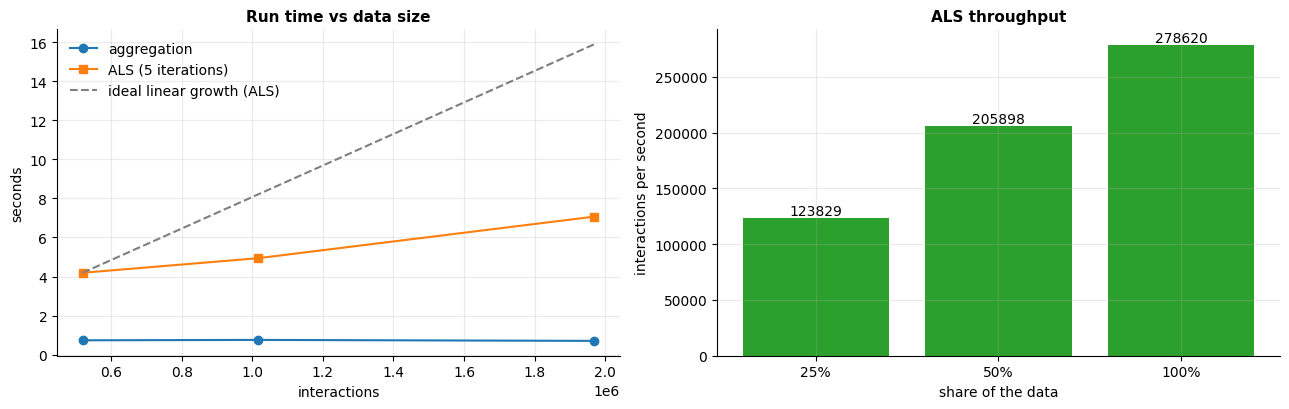

In [32]:
rows = []
for fr in (0.25, 0.5, 1.0):
    sub = inter.sample(False, fr, RANDOM_SEED) if fr < 1.0 else inter
    _, t_agg = timeit(lambda: sub.groupBy("u").agg(F.count("*"), F.sum("w")).count())
    mat = to_matrix(sub).cache(); n_row = mat.count()
    _, t_als = timeit(lambda: ALS(userCol="u", itemCol="i", ratingCol="conf", implicitPrefs=True, rank=20, maxIter=5, regParam=0.1, alpha=40.0,
                                  nonnegative=True, seed=RANDOM_SEED, numUserBlocks=20, numItemBlocks=20).fit(mat))
    mat.unpersist(); rows.append(dict(fraction=fr, interactions=n_row, aggregation_s=round(t_agg, 2), als_5_iter_s=round(t_als, 2)))
scal = pd.DataFrame(rows); R["scalability"] = scal.to_dict("records"); print(scal.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(scal["interactions"], scal["aggregation_s"], marker="o", label="aggregation", color=BLUE); ax[0].plot(scal["interactions"], scal["als_5_iter_s"], marker="s", label="ALS (5 iterations)", color=ORANGE)
ax[0].plot(scal["interactions"], scal["als_5_iter_s"].iloc[0] * scal["interactions"] / scal["interactions"].iloc[0], "--", color=GREY, label="ideal linear growth (ALS)")
ax[0].set_xlabel("interactions"); ax[0].set_ylabel("seconds"); ax[0].legend(); ax[0].set_title("Run time vs data size")
ax[1].bar([f"{int(f * 100)}%" for f in scal["fraction"]], scal["interactions"] / scal["als_5_iter_s"], color=GREEN); ax[1].bar_label(ax[1].containers[0], fmt="%.0f")
ax[1].set_xlabel("share of the data"); ax[1].set_ylabel("interactions per second"); ax[1].set_title("ALS throughput")
save("11a_scalability")

### 11.2 Summary table, scorecard and findings
Everything below is read from the dictionary `R` filled by the cells above, so the numbers always match the figures. The findings are printed as sentences that you can copy into the discussion of the report. Remember to **interpret** them: for example, a recommender that loses to popularity is still a valid scientific result if you explain the reasons.

          Component                                                      Metric                    Value
               Data                                         raw -> clean events   2,121,219 -> 2,117,673
              Spark                       RDD vs DataFrame (s) | cache speed-up     3.42 vs 0.21 | 1.68x
         Similarity                  LSH P@10 (same category) | random baseline         0.995 | 0.195637
         Similarity                      LSH recall vs exact Jaccard (8 tables)                      1.0
     ALS (implicit)                             P@10 | R@10 | HitRate@10 (test) 0.0082 | 0.0715 | 0.0807
Popularity baseline                             P@10 | R@10 | HitRate@10 (test)  0.013 | 0.1154 | 0.1249
     ALS (explicit)                       best RMSE | predict-the-mean baseline          0.6295 | 0.5777
             Hybrid best setting: trend heavy (P@10 | popularity on same users)          0.0114 | 0.0130
         Cold start                         test items 

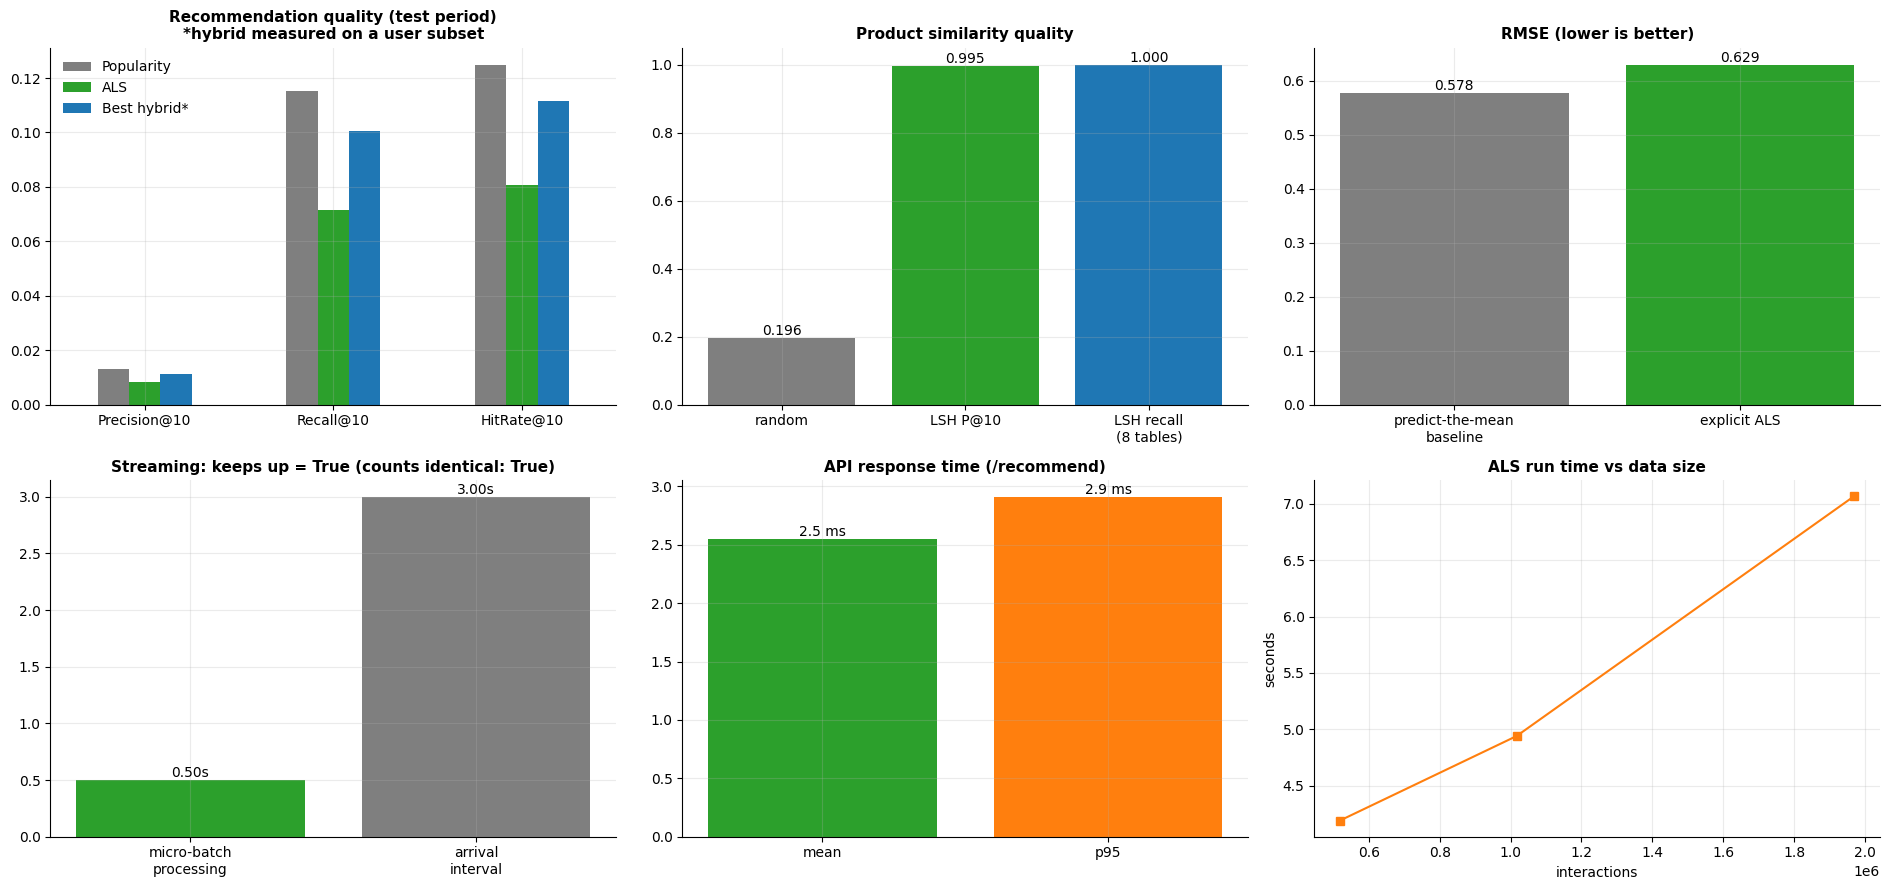


KEY FINDINGS (generated from the numbers)

1. Data: 2,121,219 raw events were cleaned to 2,117,673; only 2.3% of sessions with a view ended in a purchase, and the top 10% of products received 77% of all events (long tail).
2. Spark: the DataFrame API took 0.21s against 3.42s for the RDD version; caching changed three repeated actions by 1.68x.
3. Similarity: LSH neighbours share the query's category 0.99 of the time (random: 0.196); with 8 hash tables LSH recovered 100% of the truly similar pairs without comparing all pairs.
4. ALS: Precision@10 = 0.0082 and Recall@10 = 0.0715 against 0.0130 and 0.1154 for popularity, so ALS does not beat the popularity baseline (matrix density 9.8e-05).
5. RMSE: explicit ALS 0.629 vs 0.578 for predicting the mean rating.
6. Hybrid: best setting is 'trend heavy' with P@10 = 0.0114, against 0.0082 for ALS only and 0.0130 for popularity on the same users. 180 relevant test items were new to ALS; LSH could describe 144 of them.
7. Streaming: 90,000 event

In [33]:
rk = {r["model"]: r for r in R["ranking_test"] if r["K"] == 10}; als10, pop10 = rk["ALS (implicit)"], rk["Popularity"]
hyb = pd.DataFrame(R["hybrid"]); best_h = hyb.loc[hyb["P@10"].idxmax()]; st = R["streaming"]; api = R["api"]
summary = pd.DataFrame([
    ("Data", "raw -> clean events", f"{R['rows_raw']:,} -> {R['rows_clean']:,}"),
    ("Spark", "RDD vs DataFrame (s) | cache speed-up", f"{R['rdd_s']} vs {R['df_s']} | {R['cache_speedup']}x"),
    ("Similarity", "LSH P@10 (same category) | random baseline", f"{R['similarity']['p_at_10']} | {R['similarity']['random_baseline']}"),
    ("Similarity", "LSH recall vs exact Jaccard (8 tables)", R["lsh_recall"].get(8)),
    ("ALS (implicit)", "P@10 | R@10 | HitRate@10 (test)", f"{als10['precision']} | {als10['recall']} | {als10['hit_rate']}"),
    ("Popularity baseline", "P@10 | R@10 | HitRate@10 (test)", f"{pop10['precision']} | {pop10['recall']} | {pop10['hit_rate']}"),
    ("ALS (explicit)", "best RMSE | predict-the-mean baseline", f"{R['rmse']:.4f} | {R['rmse_baseline']}"),
    ("Hybrid", f"best setting: {best_h['model']} (P@10 | popularity on same users)", f"{best_h['P@10']} | {R['pop_same_users']['precision']:.4f}"),
    ("Cold start", "test items / users known to ALS (%)", f"{R['cold_start']['items_known_pct']} / {R['cold_start']['users_known_pct']}"),
    ("Streaming", "mean micro-batch (ms) | keeps up | counts identical", f"{st['trigger_ms']} | {st['keeps_up']} | {st['events_exact']}"),
    ("API", "mean | p95 response time (ms), all endpoints OK", f"{api['mean_ms']} | {api['p95_ms']}, {api['all_ok']}")], columns=["Component", "Metric", "Value"])
print(summary.to_string(index=False)); summary.to_csv(WORK_DIR / "summary.csv", index=False); json.dump(R, open(WORK_DIR / "results.json", "w"), indent=1, default=str)

fig, ax = plt.subplots(2, 3, figsize=(19, 9))
q = pd.DataFrame({"Popularity": [pop10[m] for m in ("precision", "recall", "hit_rate")], "ALS": [als10[m] for m in ("precision", "recall", "hit_rate")],
                  "Best hybrid*": [best_h["P@10"], best_h["R@10"], best_h["HitRate@10"]]}, index=["Precision@10", "Recall@10", "HitRate@10"])
q.plot.bar(ax=ax[0, 0], rot=0, color=[GREY, GREEN, BLUE]); ax[0, 0].set_title("Recommendation quality (test period)\n*hybrid measured on a user subset")
ax[0, 1].bar(["random", "LSH P@10", "LSH recall\n(8 tables)"], [R["similarity"]["random_baseline"], R["similarity"]["p_at_10"], R["lsh_recall"].get(8, np.nan)], color=[GREY, GREEN, BLUE])
ax[0, 1].bar_label(ax[0, 1].containers[0], fmt="%.3f"); ax[0, 1].set_title("Product similarity quality")
ax[0, 2].bar(["predict-the-mean\nbaseline", "explicit ALS"], [R["rmse_baseline"], R["rmse"]], color=[GREY, GREEN]); ax[0, 2].bar_label(ax[0, 2].containers[0], fmt="%.3f"); ax[0, 2].set_title("RMSE (lower is better)")
ax[1, 0].bar(["micro-batch\nprocessing", "arrival\ninterval"], [st["trigger_ms"] / 1000, BATCH_INTERVAL_S], color=[GREEN if st["keeps_up"] else RED, GREY]); ax[1, 0].bar_label(ax[1, 0].containers[0], fmt="%.2fs")
ax[1, 0].set_title(f"Streaming: keeps up = {st['keeps_up']} (counts identical: {st['events_exact']})")
ax[1, 1].bar(["mean", "p95"], [api["mean_ms"], api["p95_ms"]], color=[GREEN, ORANGE]); ax[1, 1].bar_label(ax[1, 1].containers[0], fmt="%.1f ms"); ax[1, 1].set_title("API response time (/recommend)")
ax[1, 2].plot(scal["interactions"], scal["als_5_iter_s"], marker="s", color=ORANGE); ax[1, 2].set_xlabel("interactions"); ax[1, 2].set_ylabel("seconds"); ax[1, 2].set_title("ALS run time vs data size")
save("11b_scorecard")

print("\nKEY FINDINGS (generated from the numbers)\n")
print(f"1. Data: {R['rows_raw']:,} raw events were cleaned to {R['rows_clean']:,}; only {R['funnel_pct'].get('purchase', float('nan')):.1f}% of sessions with a view ended in a purchase, "
      f"and the top 10% of products received {100 * R['top10pct_share']:.0f}% of all events (long tail).")
print(f"2. Spark: the DataFrame API took {R['df_s']}s against {R['rdd_s']}s for the RDD version; caching changed three repeated actions by {R['cache_speedup']}x.")
print(f"3. Similarity: LSH neighbours share the query's category {R['similarity']['p_at_10']:.2f} of the time (random: {R['similarity']['random_baseline']:.3f}); with 8 hash tables "
      f"LSH recovered {100 * R['lsh_recall'].get(8, float('nan')):.0f}% of the truly similar pairs without comparing all pairs.")
verdict = "beats" if als10["precision"] > pop10["precision"] else "does not beat"
print(f"4. ALS: Precision@10 = {als10['precision']:.4f} and Recall@10 = {als10['recall']:.4f} against {pop10['precision']:.4f} and {pop10['recall']:.4f} for popularity, so ALS {verdict} the popularity baseline "
      f"(matrix density {R['als_matrix']['density']:.1e}).")
print(f"5. RMSE: explicit ALS {R['rmse']:.3f} vs {R['rmse_baseline']:.3f} for predicting the mean rating.")
print(f"6. Hybrid: best setting is '{best_h['model']}' with P@10 = {best_h['P@10']:.4f}, against {hyb.loc[hyb['model'] == 'ALS only', 'P@10'].iloc[0]:.4f} for ALS only and {R['pop_same_users']['precision']:.4f} for popularity on the same users. "
      f"{R['cold_start_items']['new_relevant_items']:,} relevant test items were new to ALS; LSH could describe {R['cold_start_items']['lsh_can_match']:,} of them.")
print(f"7. Streaming: {st['events_total']:,} events replayed; a micro-batch took {st['trigger_ms']} ms on average ({st['rows_per_s']:,} rows/s), keeps up with the arrival rate: {st['keeps_up']}; "
      f"event counts identical to batch: {st['events_exact']}; active-user error up to {st['hll_max_rel_error']:.1%}.")
print(f"8. API: mean response {api['mean_ms']} ms, p95 {api['p95_ms']} ms; all endpoints returned 200: {api['all_ok']}.")

## 12. Discussion, limitations and conclusion

### 12.1 Discussion (one paragraph per point, each pointing at its figure)
1. **Spark internals** (`05_spark_concepts`): the DataFrame API is faster than the RDD API because the optimiser can prune columns and push filters down; the plan shows where shuffles (`Exchange`) split the job into stages; caching pays off when the same data is reused.
2. **Similarity** (`06b`, `06d`): the MinHash error shrinks as the signature gets longer, and LSH finds almost all truly similar pairs without comparing all pairs. Because many products share one text, content similarity is coarse.
3. **ALS vs popularity** (`07c`, `07e`): interpret the ranking metrics together with the matrix density, the long tail and the cold-start share (`07f`). If ALS does not beat popularity on a sample of the data, say so and explain why; also test the full data (`SAMPLE_FRACTION = 1.0`).
4. **Hybrid** (`09b`, `09c`): state whether content and trend improved the ranking, and point out the value for new items, which ALS cannot score at all.
5. **Streaming** (`08a`, `08b`): the stream keeps up if the micro-batch time is below the arrival interval; the streaming counts agree with the batch result.
6. **Serving** (`10a`): response times of a few milliseconds per request with pre-computed results; the Docker image and the cloud steps are the path to deployment.

### 12.2 Limitations
* The dataset has **no star ratings** and **no product text**; ratings are derived from behaviour and the product text is short.
* Using the category as the "expected similar" label is **partly circular**.
* The stream is a **replay** of real events with generated, time-compressed timestamps, not a live shop.
* Views show what the site displayed, not only what users wanted, so **offline metrics cannot replace an online A/B test**.
* The notebook runs on **one machine**; the multi-machine speed-up needs a cluster.
* The hand-over from stream to API uses **files**, a prototype shortcut.
* The Docker image was written but not built or deployed in this notebook.

### 12.3 Future work
Kafka as the live source, Redis or Delta tables for live results, incremental ALS updates, richer product text or image embeddings, an online A/B test, and a multi-node cloud benchmark.

### 12.4 Conclusion
Write 4 to 5 sentences: what was built (batch + speed + serving layers), the main measured results from the summary table (state honestly whether ALS and the hybrid beat the popularity baseline), what the streaming and API tests showed, and what you would do next.